# Integration of Hybrid LSTM-XGBoost with Backtesting on Indonesian Stocks

**Nama: Mohammad Hikam 'Abdul Karim**<br>
**NIM: 2211102278**

**Sistem prediksi return saham menggunakan:**
- Hybrid LSTM + XGBoost untuk prediksi
- Feature engineering dari OHLCV data
- Explainable AI (XAI) untuk interpretasi
- Portfolio optimization dengan risk management

## Cell 1: Import Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import warnings
from tabulate import tabulate

# Machine Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import xgboost as xgb

# Sklearn utilities
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error
from sklearn.covariance import LedoitWolf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Statistical analysis
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy import stats

# Settings
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully")

All libraries imported successfully


## Cell 2: Hyperparameters & Configuration

In [ ]:
# Data prameters
START_DATA = "2020-01-01"
END_DATA = "2025-11-30"
BACKTEST_START = "2020-01-02"
BACKTEST_STOP = "2025-11-30"

# Model parameters
LSTM_LOOKBACK = 84
LSTM_EPOCHS = 30
RISK_FREE_RATE = 0.0475

# Trading logic
REBAL_FREQ = "63B"  # Rebalance every ~3mo
PREDICTION_HORIZON = 21  # Predict 21day 

# Stock selection
PRED_FILTER = 0.02  # Min 2% predicted return
MIN_STOCKS = 6
MAX_STOCKS = 8

# Portfolio Constraints
MAX_WEIGHT = 0.20  # Max 20% per stock
MAX_SEKTOR_WEIGHT = 0.30  # Max 30% per sector

# Risk management
STOP_WINDOW = 42  # Lookback for stop-loss calculation
STOP_MIN_CUT = 0.05  # Min 5% stop-loss
STOP_MAX_CUT = 0.12  # Max 12% stop-loss
STOP_MULTIPLIER = 4  # Volatility multiplier

# Transaction fee/cost
BUY_FEE_RATE = 0.0020  # 0.2%
SELL_FEE_RATE = 0.0020  # 0.2%

print("Configuration loaded")
print(f" Backtest: {BACKTEST_START} to {BACKTEST_STOP}")
print(f" Rebalance: {REBAL_FREQ}")
print(f" Portfolio: {MIN_STOCKS}-{MAX_STOCKS} stocks")

Configuration loaded
 Backtest: 2020-01-02 to 2025-11-30
 Rebalance: 63B
 Portfolio: 6-8 stocks


## Cell 3: Stock Universe & Sector Mapping

In [ ]:
# LQ45 stock universe
LQ45_TICKERS = [
    'ADRO.JK', 'AKRA.JK', 'AMMN.JK', 'AMRT.JK', 'ANTM.JK',
    'ASII.JK', 'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK',
    'BRPT.JK', 'CPIN.JK', 'CTRA.JK', 'EXCL.JK', 'GOTO.JK',
    'ICBP.JK', 'INCO.JK', 'INDF.JK', 'INTP.JK', 'ITMG.JK',
    'JPFA.JK', 'KLBF.JK', 'MDKA.JK', 'MEDC.JK', 'PGAS.JK',
    'PTBA.JK', 'SIDO.JK', 'SMGR.JK', 'TLKM.JK', 'UNTR.JK',
    'UNVR.JK', 'ESSA.JK', 'BBYB.JK', 'MIKA.JK', 'TOWR.JK',
    'HRUM.JK', 'INKP.JK', 'TKIM.JK', 'BUKA.JK', 'PWON.JK',
    'MAPA.JK', 'ERAA.JK', 'ELSA.JK', 'SMRA.JK', 'WSKT.JK'
]

# Sector classification
SEKTOR_DICT = {
    'ADRO.JK': 'Energi', 'AKRA.JK': 'Energi', 'AMMN.JK': 'Pertambangan',
    'AMRT.JK': 'Konsumer', 'ANTM.JK': 'Pertambangan',
    'ASII.JK': 'Industri', 'BBCA.JK': 'Bank', 'BBNI.JK': 'Bank', 
    'BBRI.JK': 'Bank', 'BMRI.JK': 'Bank',
    'BRPT.JK': 'Industri', 'CPIN.JK': 'Konsumer', 'CTRA.JK': 'Properti', 
    'EXCL.JK': 'Telekom', 'GOTO.JK': 'Tech',
    'ICBP.JK': 'Konsumer', 'INCO.JK': 'Pertambangan', 'INDF.JK': 'Konsumer', 
    'INTP.JK': 'Industri', 'ITMG.JK': 'Energi',
    'JPFA.JK': 'Konsumer', 'KLBF.JK': 'Kesehatan', 'MDKA.JK': 'Pertambangan', 
    'MEDC.JK': 'Energi', 'PGAS.JK': 'Energi',
    'PTBA.JK': 'Energi', 'SIDO.JK': 'Kesehatan', 'SMGR.JK': 'Industri', 
    'TLKM.JK': 'Telekom', 'UNTR.JK': 'Industri',
    'UNVR.JK': 'Konsumer', 'ESSA.JK': 'Industri', 'BBYB.JK': 'Bank', 
    'MIKA.JK': 'Kesehatan', 'TOWR.JK': 'Infrastruktur',
    'HRUM.JK': 'Energi', 'INKP.JK': 'Industri', 'TKIM.JK': 'Industri', 
    'BUKA.JK': 'Tech', 'PWON.JK': 'Properti',
    'MAPA.JK': 'Retail', 'ERAA.JK': 'Retail', 'ELSA.JK': 'Energi', 
    'SMRA.JK': 'Properti', 'WSKT.JK': 'Konstruksi'
}

# Count stocks per sector
sector_counts = pd.Series(SEKTOR_DICT).value_counts()

print(f"Universe: {len(LQ45_TICKERS)} stocks")
print(f"\nSector Distribution:")
for sector, count in sector_counts.items():
    print(f"  - {sector}: {count} stocks")

Universe: 45 stocks

Sector Distribution:
  - Energi: 8 stocks
  - Industri: 8 stocks
  - Konsumer: 6 stocks
  - Bank: 5 stocks
  - Pertambangan: 4 stocks
  - Properti: 3 stocks
  - Kesehatan: 3 stocks
  - Telekom: 2 stocks
  - Tech: 2 stocks
  - Retail: 2 stocks
  - Infrastruktur: 1 stocks
  - Konstruksi: 1 stocks


## Cell 4: Data Loader Class

In [ ]:
class DataProcessor:
    """Load and process OHLCV data from CSV"""
    
    def __init__(self, tickers, csv_path):
        self.tickers = tickers
        self.csv_path = csv_path
        self.data = None
        self.ohlcv = None
        self.close_prices = None
        self._missing_before = 0
    
    def load_data(self):
        """Load CSV with multi-level columns"""
        print(f"Source file : {self.csv_path}")

        try:
            df = pd.read_csv(
                self.csv_path,
                header=[0,1],
                index_col=0,
                parse_dates=True
            )

            df.columns = pd.MultiIndex.from_tuples([
                (lvl0, str(lvl1).replace(".JK", ""))
                for lvl0, lvl1 in df.columns
            ])

            self.data = df

            total_missing = df.isnull().sum().sum()

            print("\nDataset summary")
            print(f" Rows       : {df.shape[0]:,}")
            print(f" Columns    : {df.shape[1]}")
            print(f" Date range : {df.index[0].date()} → {df.index[-1].date()}")
            print(f" Missing    : {total_missing:,}")

            print("\nSample columns:")
            print(" ", list(df.columns[:6]), "...")

            print("-"*60)

            return True

        except Exception as e:
            print(f" Failed loading data: {e}")
            return False

    def extract_ohlcv(self):
        self._missing_before = self.data.isnull().sum().sum()  
        df = self.data.copy()                                  
        df = df.ffill()                             
        self.ohlcv = df
        return df
    
    def extract_close_prices(self):

        if "Adj Close" in self.ohlcv.columns.get_level_values(0):
            close = self.ohlcv["Adj Close"]
        else:
            close = self.ohlcv["Close"]

        close = close.ffill()
        self.close_prices = close

        missing_after = self.ohlcv.isnull().sum().sum()

        print("\nDATA CLEANING")
        print(f" Missing before : {self._missing_before:,}")
        print(f" Missing after  : {missing_after:,}")
        print(f" Filled         : {self._missing_before - missing_after:,}")

        print("\nClose price preview")

        preview = close.iloc[:5, :6].round(2)
        print(preview)

        print("-"*60)

        return close
    
    def get_benchmark(self, start_date, end_date):
        """Load IHSG benchmark"""
        print(" Loading IHSG benchmark")
        try:
            bm = pd.read_csv("IHSG.csv", header=[0, 1], index_col=0, parse_dates=True)
            if 'Adj Close' in bm.columns:
                price = bm['Adj Close']['^JKSE']
            elif 'Close' in bm.columns:
                price = bm['Close']['^JKSE']
            else:
                price = bm.iloc[:, 0]
            price = price.astype(float).sort_index()
            return price.loc[start_date:end_date]
        except Exception as e:
            print(f" Benchmark load failed: {e}")
            print("  Using average return fallback")
            idx = pd.date_range(start_date, end_date, freq="D")
            return pd.Series(np.cumprod(np.ones(len(idx)) * 1.0005), index=idx)

print("Data Loader class defined")

Data Loader class defined


## Cell 5: Feature Engineering Class

In [ ]:
class FeatureEngineer:
    """Create technical and price-based features"""
    
    def __init__(self, lookback_period=126):
        self.lookback_period = lookback_period
        self.ohlcv = None
        self._clip_bounds = None
    
    def _price_features(self, prices):
        """Calculate price-based features"""
        f = pd.DataFrame(index=prices.index)
        ret = prices.pct_change()
        
        # Momentum features
        for p in [5, 10, 21, 63]:
            f[f"momentum_{p}d"] = prices.pct_change(p)
        
        # Volatility
        f["volatility_21d"] = ret.rolling(21).std()
        f["vol_adj_mom"] = f["momentum_21d"] / (f["volatility_21d"] + 1e-10)
        
        # RSI
        delta = prices.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = -delta.clip(upper=0).rolling(14).mean()
        rs = gain / (loss + 1e-10)
        f["rsi"] = 100 - (100 / (1 + rs))
        f["rsi_norm"] = (f["rsi"] - 50) / 50
        
        # Moving averages
        f["ma_20_50"] = prices.rolling(20).mean() / (prices.rolling(50).mean() + 1e-10)
        
        # Trend strength
        f["trend_strength"] = abs(f["momentum_21d"]) / (f["volatility_21d"] + 1e-10)
        
        # Price position
        f["price_vs_high"] = prices / (prices.rolling(63).max() + 1e-10)
        
        # Drawdown
        cummax = prices.expanding().max()
        f["drawdown"] = (prices - cummax) / (cummax + 1e-10)
        
        # Log return statistics
        logret = np.log(prices / prices.shift(1))
        f["logret_21_mean"] = logret.rolling(21).mean()
        f["logret_21_std"] = logret.rolling(21).std()
        
        return f
    
    def _ohlcv_features(self, stock, end_date):
        """Calculate OHLCV-based features (FIXED: volume ratio only)"""
        df = self.ohlcv.xs(stock, level=1, axis=1).loc[:end_date]
        price = df["Adj Close"] if "Adj Close" in df else df["Close"]
        
        f = pd.DataFrame(index=price.index)
        
        # Price range
        f["daily_range"] = (df["High"] - df["Low"]) / (price + 1e-10)
        
        price_scale = price.mean() # scaling the stock price itself
        f["body_ratio"] = abs(price - df["Open"]) / (df["High"] - df["Low"] + price_scale * 0.001).clip(lower=0.01)
        f["body_ratio"] = f["body_ratio"].clip(0, 1)
        
        # Volume ratio 
        volume_sma = df["Volume"].rolling(20).mean()
        if len(volume_sma) > 0 and volume_sma.iloc[-1] > 0:
            volume_ratio = (df["Volume"].values / volume_sma.values)
            f["volume_ratio"] = pd.Series(volume_ratio, index=df.index)
        else:
            f["volume_ratio"] = pd.Series(1.0, index=df.index)
        
        # Log transform to reduce skew
        f["volume_ratio_log"] = np.log1p(f["volume_ratio"])
        
        return f
    
    def check_outliers(self, X):
        """Identify features with extreme outliers"""
        print("\nOUTLIER ANALYSIS")
        print("-"*60)
        
        for col in X.columns:
            q99 = X[col].quantile(0.99)
            q01 = X[col].quantile(0.01)
            max_val = X[col].max()
            min_val = X[col].min()
            
            # check upper outlier
            if max_val > q99 * 2:  # > 2x 99th percentile
                print(f"- {col}: max {max_val:.2f} vs 99th {q99:.2f} ({(max_val/q99-1)*100:.1f}% higher than 99th percentile)")
            
            # check upper outliers
            if min_val < q01 * 2 and min_val < 0:
                print(f"- {col}: min {min_val:.2f} vs 1st {q01:.2f}")
        
        print("-"*60)
    
    def _fit_clip_bounds(self, X, lower_q=0.01, upper_q=0.99):
        """Fit clipping boundaries from the initial training data, call once only"""
        self._clip_bounds = {}
        for col in X.columns:
            self._clip_bounds[col] = (
                X[col].quantile(lower_q),
                X[col].quantile(upper_q)
            )

    def _clean_features(self, X):
        """Apply winsorization using the pre-fitted bounds"""
        if self._clip_bounds is None:
            raise ValueError("Call _fit_clip_bounds() before _clean_features()")
        X_clean = X.copy()
        for col in X_clean.columns:
            if col in self._clip_bounds:
                lo, hi = self._clip_bounds[col]
                X_clean[col] = X_clean[col].clip(lo, hi)
        return X_clean
    
    def create_dataset(self, close_df, as_of_date):
        """Create ML-ready dataset"""
        X_all, y_all = [], []
        future_ret = close_df.pct_change(PREDICTION_HORIZON).shift(-PREDICTION_HORIZON)
        
        for stock in close_df.columns:
            prices = close_df[stock][:as_of_date].dropna()
            if len(prices) < self.lookback_period:
                continue
            
            f_price = self._price_features(prices)
            f_ohlcv = self._ohlcv_features(stock, as_of_date)
            feats = pd.concat([f_price, f_ohlcv], axis=1)
            
            comb = pd.concat(
                [feats, future_ret[stock][:as_of_date].rename("target")],
                axis=1
            ).dropna()
            
            if len(comb) >= 227:
                X_all.append(comb.drop("target", axis=1))
                y_all.append(comb["target"])
        
        if X_all:
            X = pd.concat(X_all)
            y = pd.concat(y_all)

            self.check_outliers(X) # Check outliers before cleaning

            # fit only once at the first rebalancing
            if self._clip_bounds is None:
                self._fit_clip_bounds(X)

            X = self._clean_features(X) # Winsorizaation
            return X, y
        return None, None

    def print_feature_summary(self, X):
        """Print feature statistics table after engineering"""
        feature_meta = {
            "momentum_5d":     "Momentum (5 Hari)",
            "momentum_10d":    "Momentum (10 Hari)",
            "momentum_21d":    "Momentum (21 Hari)",
            "momentum_63d":    "Momentum (63 Hari)",
            "volatility_21d":  "Volatilitas Historis (21 Hari)",
            "vol_adj_mom":     "Risk-Adjusted Momentum",
            "rsi":             "Relative Strength Index (RSI)",
            "rsi_norm":        "RSI Ternormalisasi",
            "ma_20_50":        "Rasio MA20/MA50",
            "trend_strength":  "Indikator Kekuatan Tren",
            "price_vs_high":   "Harga vs High 63 Hari",
            "drawdown":        "Current Drawdown",
            "logret_21_mean":  "Rata-rata Log Return (21 Hari)",
            "logret_21_std":   "Standar Deviasi Log Return",
            "daily_range":     "Daily Trading Range",
            "body_ratio":      "Rasio Tubuh Candlestick",
            "volume_ratio":    "Rasio Volume Transaksi",
            "volume_ratio_log":"Log Rasio Volume",
        }

        desc = X.describe().T  # index = feature names
        rows = []
        for code, academic in feature_meta.items():
            if code in desc.index:
                rows.append({
                    "Feature Name":      code,
                    "Nama Fitur":  academic,
                    "Mean":                   f"{desc.loc[code, 'mean']:.6f}",
                    "Std. Dev":               f"{desc.loc[code, 'std']:.6f}",
                    "Min":                    f"{desc.loc[code, 'min']:.6f}",
                    "Max":                    f"{desc.loc[code, 'max']:.6f}",
                })

        summary_df = pd.DataFrame(rows)
        summary_df.index = range(1, len(summary_df) + 1)

        print("\nFEATURE ENGINEERING")
        print("-"*60)
        print(f" Total samples  : {len(X):,} rows")
        print(f" Total features : {len(X.columns)} columns")
        print("-"*85)
        print(summary_df.to_string())
        print("-"*85 + "\n")

        
print("Feature Engineering class defined")

Feature Engineering class defined


## Cell 6: Hybrid LSTM-XGBoost Predictor

In [ ]:
class HybridPredictor:
    """Ensemble predictor combining LSTM and XGBoost"""
    
    def __init__(self, lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS):
        self.lookback = lookback
        self.lstm_epochs = lstm_epochs
        self.scaler = RobustScaler()
        self.lstm_model = None
        self.xgb_model = None
        self.feature_names = None
        self.lstm_weight = 0.5
        self.xgb_weight = 0.5
        self._X_lstm_val = None
        self._y_val = None
        self._X_xgb_val = None
        self.X_scaled_full = None
    
    def _build_lstm(self, input_shape):
        """Build LSTM architecture"""
        model = Sequential([
            LSTM(64, return_sequences=True, input_shape=input_shape),
            BatchNormalization(),
            LSTM(32),
            Dense(16, activation="relu"),
            Dropout(0.3),
            Dense(1)
        ])
        model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
        return model
    
    def train(self, X: pd.DataFrame, y: pd.Series, first_rebalance=False):
        """Train both LSTM and XGBoost models"""
        X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
        y = y.astype(float)
        self.feature_names = X.columns.tolist()
        
        # Scale features
        Xs = self.scaler.fit_transform(X)
        yv = y.values
        
        # Create sequences for LSTM
        X_lstm, y_lstm, X_xgb = [], [], []
        for i in range(self.lookback, len(Xs)):
            X_lstm.append(Xs[i - self.lookback:i])
            y_lstm.append(yv[i])
            X_xgb.append(Xs[i])
        
        X_lstm = np.array(X_lstm)
        y_lstm = np.array(y_lstm)
        X_xgb = np.array(X_xgb)
        
        if len(X_lstm) < 100:
            print("Insufficient data for training")
            return False
        
        # Train/val split
        split = int(0.8 * len(X_lstm))
        
        # Train LSTM
        self.lstm_model = self._build_lstm((self.lookback, X_lstm.shape[2]))
        self.lstm_model.fit(
            X_lstm[:split], y_lstm[:split],
            validation_data=(X_lstm[split:], y_lstm[split:]),
            epochs=self.lstm_epochs,
            batch_size=32,
            callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
            verbose=0
        )
        
        # Train XGBoost
        self.xgb_model = xgb.XGBRegressor(
            n_estimators=300, max_depth=4, learning_rate=0.02,
            subsample=0.8, colsample_bytree=0.8, random_state=42
        )
        self.xgb_model.fit(X_xgb[:split], y_lstm[:split])
        
        # Calculate ensemble weights based on validation performance
        lstm_pred = self.lstm_model.predict(X_lstm[split:], verbose=0).flatten()
        xgb_pred = self.xgb_model.predict(X_xgb[split:])
        
        mse_lstm = mean_squared_error(y_lstm[split:], lstm_pred)
        mse_xgb = mean_squared_error(y_lstm[split:], xgb_pred)
        
        inv_lstm = 1 / (mse_lstm + 1e-9)
        inv_xgb = 1 / (mse_xgb + 1e-9)
        self.lstm_weight = inv_lstm / (inv_lstm + inv_xgb)
        self.xgb_weight = inv_xgb / (inv_lstm + inv_xgb)
        
        hybrid_pred = (
            self.lstm_weight * lstm_pred
            + self.xgb_weight * xgb_pred
        )

        mse_hybrid = mean_squared_error(y_lstm[split:], hybrid_pred)
        
        
        print("\nMODEL TRAINING RESULTS")
        print("-"*60)
        print(f" Val MSE: LSTM={mse_lstm:.6f} | XGB={mse_xgb:.6f}")
        print(f" Weights: LSTM={self.lstm_weight:.2f} | XGB={self.xgb_weight:.2f}")
        print(f" Hybrid MSE = {mse_hybrid:.6f}")
        
        # Store validation data for XAI
        self._X_lstm_val = X_lstm[split:]
        self._y_val = y_lstm[split:]
        self._X_xgb_val = X_xgb[split:]
        self.X_scaled_full = Xs
        
        return True
    
    def predict(self, X_latest: pd.DataFrame) -> np.ndarray:
        """Make predictions using ensemble"""
        X_latest = X_latest.fillna(0)
        Xs_latest = self.scaler.transform(X_latest)
        
        # XGBoost prediction
        xgb_pred = self.xgb_model.predict(Xs_latest)
        
        # LSTM prediction with historical context
        lstm_pred = []
        hist = self.X_scaled_full
        
        if len(hist) < self.lookback - 1:
            raise ValueError("Insufficient historical data for LSTM")
        
        for i in range(len(Xs_latest)):
            seq = np.vstack([
                hist[-(self.lookback - 1):],
                Xs_latest[i]
            ])
            seq = seq.reshape(1, self.lookback, -1)
            pred = self.lstm_model.predict(seq, verbose=0)[0][0]
            lstm_pred.append(pred)
        
        lstm_pred = np.array(lstm_pred)
        
        # Ensemble
        hybrid_pred = self.lstm_weight * lstm_pred + self.xgb_weight * xgb_pred
        return hybrid_pred

print("Hybrid Predictor class defined")

Hybrid Predictor class defined


## Cell 7: Stock-Specific XAI Engine

In [7]:
class StockSpecificXAI:
    """Explain individual stock selections"""
    
    def __init__(self):
        self.stock_explanations_history = []
    
    def explain_stock_selection(self, stock, features, prediction,
                                universe_features=None, universe_stats=None):
        """Generate explanation for a single stock"""
        feature_ranking = features.abs().sort_values(ascending=False)
        
        # Analyze all features
        all_features_analysis = {}
        for feat in features.index:
            feat_value = features[feat]
            all_features_analysis[feat] = {
                'value': feat_value,
                'abs_value': abs(feat_value),
                'percentile': 50
            }
            
            if universe_stats is not None and feat in universe_stats.columns:
                stats = universe_stats[feat]
                if stats['std'] > 0:
                    z_score = (feat_value - stats['mean']) / stats['std']
                    all_features_analysis[feat]['z_score'] = z_score
                    all_features_analysis[feat]['percentile'] = self._calculate_percentile(feat_value, stats)
        
        # Find extreme features
        extreme_features = {}
        for feat, analysis in all_features_analysis.items():
            if 'z_score' in analysis and abs(analysis['z_score']) > 1.5:
                extreme_features[feat] = analysis
        
        result = {
            'stock': stock,
            'prediction': prediction,
            'prediction_percent': prediction * 100,
            'top_features': {k: features[k] for k in feature_ranking.head(10).index},
            'all_features': all_features_analysis,
            'feature_values': features.to_dict(),
            'extreme_features': extreme_features,
            'category': self._categorize_stock(features),
            'explanation': self._generate_simple_explanation(
                stock, prediction, features, extreme_features, self._categorize_stock(features)
            )
        }
        return result
    
    def _categorize_stock(self, features):
        """Categorize stock based on features"""
        categories = []
        
        momentum_features = [f for f in features.index if 'momentum' in f]
        if momentum_features:
            avg_momentum = features[momentum_features].mean()
            if avg_momentum > 0.05:
                categories.append('High Momentum')
            elif avg_momentum < -0.05:
                categories.append('Negative Momentum')
        
        if 'price_vs_high' in features.index:
            if features['price_vs_high'] < 0.7:
                categories.append('Value Play')
            elif features['price_vs_high'] > 0.9:
                categories.append('Near High')
        
        if 'volatility_21d' in features.index and features['volatility_21d'] > 0.03:
            categories.append('High Volatility')
        
        if 'trend_strength' in features.index and features['trend_strength'] > 1.5:
            categories.append('Strong Trend')
        
        if 'volume_ratio' in features.index and features['volume_ratio'] > 1.5:
            categories.append('High Volume')
        
        return categories if categories else ['Neutral']
    
    def _generate_simple_explanation(self, stock, prediction, features,
                                      extreme_features, category):
        """Generate human-readable explanation"""
        explanation = f"{stock}: Predicted return {prediction*100:.1f}%"
        
        if category:
            explanation += f" ({', '.join(category)})"
        
        sorted_features = features.abs().sort_values(ascending=False)
        top_3 = sorted_features.head(3).index
        
        if top_3.any():
            feat_names = [self._feature_to_english(f) for f in top_3]
            feat_values = [f"{features[f]:.3f}" for f in top_3]
            feat_str = ", ".join([f"{name}: {val}" for name, val in zip(feat_names, feat_values)])
            explanation += f". Key factors: {feat_str}"
        
        if extreme_features:
            extreme_list = []
            for feat, stats in list(extreme_features.items())[:2]:
                direction = "high" if stats.get('z_score', 0) > 0 else "low"
                feat_name = self._feature_to_english(feat)
                extreme_list.append(f"{feat_name} {direction}")
            if extreme_list:
                explanation += f". Extreme: {', '.join(extreme_list)}"
        
        return explanation
    
    def _feature_to_english(self, feature_name):
        """Convert feature names to Indonesian"""
        mapping = {
            'momentum_5d': 'Momentum 5 hari', 'momentum_10d': 'Momentum 10 hari',
            'momentum_21d': 'Momentum 21 hari', 'momentum_63d': 'Momentum 63 hari',
            'volatility_21d': 'Volatilitas', 'vol_adj_mom': 'Momentum teradjust risiko',
            'rsi': 'RSI', 'rsi_norm': 'RSI normalized', 'ma_20_50': 'Rasio MA20/MA50',
            'trend_strength': 'Kekuatan trend', 'price_vs_high': 'Harga vs high 63 hari',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Return log 21 hari',
            'logret_21_std': 'Deviasi return', 'daily_range': 'Range harian',
            'body_ratio': 'Rasio body candle', 'volume_ratio': 'Rasio volume'
        }
        return mapping.get(feature_name, feature_name)
    
    def _calculate_percentile(self, value, stats):
        """Calculate percentile rank"""
        if stats['std'] == 0:
            return 50
        z = (value - stats['mean']) / stats['std']
        percentile = 50 + (z * 100 / 3)
        return max(0, min(100, percentile))

print("Stock-Specific XAI class defined")

Stock-Specific XAI class defined


## Cell 8: Rebalance XAI Engine

In [8]:
class RebalanceXAIEngine:
    """Analyze feature importance and explain portfolio decisions"""
    
    def __init__(self, max_local_samples=5):
        self.max_local_samples = max_local_samples
        self.stock_xai = StockSpecificXAI()
        self.xai_history = []
        self.feature_importance_history = []
    
    def get_hybrid_feature_importance(self, predictor):
        """Calculate feature importance from both models"""
        print("Calculating hybrid feature importance...")
        
        # XGBoost importance
        xgb_importance = predictor.xgb_model.feature_importances_
        
        # LSTM gradient-based importance
        lstm_importance = self._get_lstm_importance(predictor)
        
        # Normalize and combine
        xgb_norm = xgb_importance / (xgb_importance.sum() + 1e-10)
        lstm_norm = lstm_importance / (lstm_importance.sum() + 1e-10)
        
        hybrid_importance = (
            predictor.lstm_weight * lstm_norm +
            predictor.xgb_weight * xgb_norm
        )
        
        importance_series = pd.Series(
            hybrid_importance,
            index=predictor.feature_names[:len(hybrid_importance)]
        ).sort_values(ascending=False)
        
        return importance_series
    
    def _get_lstm_importance(self, predictor):
        """Calculate LSTM feature importance using gradients"""
        if predictor._X_lstm_val is None or len(predictor._X_lstm_val) == 0:
            return np.ones(len(predictor.feature_names)) / len(predictor.feature_names)
        
        n_samples = min(5, len(predictor._X_lstm_val))
        X_sample_lstm = predictor._X_lstm_val[:n_samples]
        
        importance_list = []
        for i in range(n_samples):
            seq = X_sample_lstm[i:i+1]
            seq_tensor = tf.convert_to_tensor(seq, dtype=tf.float32)
            
            with tf.GradientTape() as tape:
                tape.watch(seq_tensor)
                prediction = predictor.lstm_model(seq_tensor, training=False)
            
            gradients = tape.gradient(prediction, seq_tensor)
            sample_importance = tf.reduce_mean(tf.abs(gradients), axis=[0, 1]).numpy()
            importance_list.append(sample_importance)
        
        return np.mean(importance_list, axis=0)
    
    def run(self, predictor):
        """Run full XAI analysis"""
        
        if (predictor.xgb_model is None or predictor.lstm_model is None or
            predictor.feature_names is None):
            print(" Models not trained yet")
            return {
                "global_hybrid": pd.Series(),
                "category_summary": []
            }
        
        try:
            hybrid_importance = self.get_hybrid_feature_importance(predictor)
            self.save_feature_importance_to_history(hybrid_importance, pd.Timestamp.now())

            if not hybrid_importance.empty:

                print("\nModel Contribution (Hybrid Weight)")
                print(f" LSTM     : {predictor.lstm_weight:.2f} | XGBoost  : {predictor.xgb_weight:.2f}")
                
                print("\nFEATURE RANKING")
                print("-"*60)
                # Top 15 features   
                top_features = hybrid_importance.head(15)
                print("\nTop 15 Most Important Features")
                print("-" * 60)
                for i, (feat, imp) in enumerate(top_features.items(), 1):
                    percentage = imp * 100
                    readable = self._get_readable_feature_name(feat)
                    print(f" {i:2d}. {readable:30s}: {imp:.6f} ({percentage:5.1f}%)")
                
                # Category summary
                category_summary = self.get_feature_category_summary(hybrid_importance)
                print("\nFeature Importance by Category")
                print("-" * 60)
                for cat_data in category_summary:
                    category = cat_data['category']
                    percentage = cat_data['percentage']
                    top_feats = ", ".join(cat_data['top_features'])
                    print(f" - {category:25s}: {percentage:.1f}% - {top_feats}")
                
                self._plot_feature_importance(hybrid_importance)
            
            return {
                "global_hybrid": hybrid_importance,
                "category_summary": category_summary if 'category_summary' in locals() else []
            }
        except Exception as e:
            print(f" Feature importance error: {e}")
            return {"global_hybrid": pd.Series(), "category_summary": []}
    
    def _get_readable_feature_name(self, feature_name):
        """Convert to readable format"""
        mapping = {
            'momentum_5d': 'Momentum 5D', 'momentum_10d': 'Momentum 10D',
            'momentum_21d': 'Momentum 21D', 'momentum_63d': 'Momentum 63D',
            'volatility_21d': 'Volatility 21D', 'vol_adj_mom': 'Risk-Adj Momentum',
            'rsi': 'RSI', 'rsi_norm': 'RSI Normalized', 'ma_20_50': 'MA20/MA50 Ratio',
            'trend_strength': 'Trend Strength', 'price_vs_high': 'Price vs 63D High',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Log Return Mean',
            'logret_21_std': 'Log Return Std', 'daily_range': 'Daily Range',
            'body_ratio': 'Candle Body Ratio', 'volume_ratio': 'Volume Ratio'
        }
        return mapping.get(feature_name, feature_name[:25])
    
    def _plot_feature_importance(self, importance_series):
        """Visualize feature importance"""
        try:
            if importance_series.empty:
                return
            
            top_n = min(12, len(importance_series))
            top_features = importance_series.head(top_n)
            
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
            
            # Bar chart
            readable_names = [self._get_readable_feature_name(f) for f in top_features.index]
            bars = ax1.barh(range(len(top_features)), top_features.values)
            ax1.set_yticks(range(len(top_features)))
            ax1.set_yticklabels(readable_names, fontsize=9)
            ax1.set_xlabel('Importance Score')
            ax1.set_title(f'Top {top_n} Feature Importance', fontweight='bold')
            ax1.grid(True, alpha=0.3, axis='x')
            
            for bar, imp in zip(bars, top_features.values):
                bar.set_color('green' if imp > 0.05 else 'orange' if imp > 0.02 else 'red')
            
            # Pie chart for categories
            categories = {
                'Momentum Features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
                'Volatility Features': ['volatility_21d', 'vol_adj_mom'],
                'Technical Indicators': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
                'Price Action': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
                'Return Statistics': ['logret_21_mean', 'logret_21_std'],
                'Volume Features': ['volume_ratio', 'volume_ratio_log']
            }
            
            cat_data = {}
            for cat, feats in categories.items():
                valid_feats = [f for f in feats if f in importance_series.index]
                if valid_feats:
                    cat_data[cat] = importance_series[valid_feats].sum()
            
            if cat_data:
                cat_series = pd.Series(cat_data)
                colors = plt.cm.Set3(np.linspace(0, 1, len(cat_series)))
                ax2.pie(cat_series.values, labels=cat_series.index, autopct='%1.1f%%',
                       colors=colors, startangle=90)
                ax2.set_title('Importance by Category', fontweight='bold')
            
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f" Plot error: {e}")
    
    def explain_selected_stocks(self, selected_stocks, latest_features_df,
                               predictions, universe_features=None):
        """Generate stock-specific explanations"""
        print("\nMODEL EXPLANATIONS (Selected Stocks)")
        print("-"*60)
        print(f"Stocks analyzed : {len(selected_stocks)}")
        
        universe_stats = None
        if universe_features is not None:
            universe_stats = self._calculate_universe_stats(universe_features)
        
        explanations = {}
        for stock in selected_stocks:
            if stock in latest_features_df.index:
                features = latest_features_df.loc[stock]
                prediction = predictions.get(stock, 0)
                
                explanation = self.stock_xai.explain_stock_selection(
                    stock=stock, features=features, prediction=prediction,
                    universe_stats=universe_stats
                )
                explanations[stock] = explanation
                print(f" - {explanation['explanation']}")
        
        self.xai_history.append({
            'rebalance_date': pd.Timestamp.now(),
            'selected_stocks': selected_stocks,
            'explanations': explanations
        })
        return explanations
    
    def _calculate_universe_stats(self, universe_features):
        """Calculate statistics across all stocks"""
        stats = {}
        for col in universe_features.columns:
            stats[col] = {
                'mean': universe_features[col].mean(),
                'std': universe_features[col].std(),
                'min': universe_features[col].min(),
                'max': universe_features[col].max(),
                'median': universe_features[col].median()
            }
        return pd.DataFrame(stats)
    
    def get_feature_category_summary(self, importance_series):
        """Summarize importance by feature category"""
        feature_categories = {
            'Momentum Features': {
                'features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
            },
            'Volatility Features': {
                'features': ['volatility_21d', 'vol_adj_mom'],
            },
            'Technical Indicators': {
                'features': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
            },
            'Price Action': {
                'features': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
            },
            'Return Statistics': {
                'features': ['logret_21_mean', 'logret_21_std'],
            },
            'Volume Features': {
                'features': ['volume_ratio', 'volume_ratio_log'],
            }
        }
        
        results = []
        for category, cat_info in feature_categories.items():
            valid_features = [f for f in cat_info['features'] if f in importance_series.index]
            if valid_features:
                cat_importance = importance_series[valid_features].sum()
                cat_percentage = cat_importance * 100
                top_features_in_cat = importance_series[valid_features].nlargest(2)
                top_feature_names = [self._get_readable_feature_name(f) for f in top_features_in_cat.index]
                
                results.append({
                    'category': category,
                    'percentage': cat_percentage,
                    'top_features': top_feature_names,
                    'feature_count': len(valid_features)
                })
        
        results.sort(key=lambda x: x['percentage'], reverse=True)
        return results
    
    def save_feature_importance_to_history(self, importance_series, rebalance_date):
        """Save for aggregate analysis"""
        if importance_series is not None and not importance_series.empty:
            self.feature_importance_history.append({
                'date': rebalance_date,
                'importance': importance_series.copy(),
                'top_features': importance_series.head(10).to_dict()
            })

print("Rebalance XAI Engine class defined")

Rebalance XAI Engine class defined


## Cell 9: Portfolio Optimizer

In [ ]:
class PortfolioOptimizer:
    """Optimize portfolio weights using Sharpe ratio maximization"""
    
    def __init__(self, risk_free_rate=RISK_FREE_RATE):
        self.risk_free_rate = risk_free_rate
    
    def optimize(self, expected_returns, cov_matrix):
        """Find optimal weights via SLSQP optimization"""
        n = len(expected_returns)
        mu = expected_returns.values if hasattr(expected_returns, 'values') else expected_returns
        
        # Apply shrinkage if covariance matrix is singular
        try:
            np.linalg.inv(cov_matrix)
        except np.linalg.LinAlgError:
            print("Singular covariance matrix, applying shrinkage")
            cov_matrix = LedoitWolf().fit(
                cov_matrix.values if isinstance(cov_matrix, pd.DataFrame) else cov_matrix
            ).covariance_
        
        def negative_sharpe(weights):
            port_return = np.sum(mu * weights)
            port_vol = np.sqrt(weights.T @ cov_matrix @ weights)
            sharpe = (port_return - self.risk_free_rate/252) / (port_vol + 1e-9)
            return -sharpe
        
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0.01, MAX_WEIGHT) for _ in range(n)]
        init_weights = np.array([1/n] * n)
        
        result = minimize(
            negative_sharpe, init_weights, method='SLSQP',
            bounds=bounds, constraints=constraints,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        
        if result.success:
            weights = pd.Series(result.x, index=expected_returns.index)
            weights = weights[weights > 0.01]
            if len(weights) == 0:
                return self._risk_parity_fallback(expected_returns, cov_matrix)
            return weights / weights.sum()
        else:
            print("Optimization failed, using risk parity")
            return self._risk_parity_fallback(expected_returns, cov_matrix)
    
    def _risk_parity_fallback(self, expected_returns, cov_matrix):
        """Simple inverse volatility weighting"""
        vol = np.sqrt(np.diag(cov_matrix))
        weights = 1 / vol
        weights /= weights.sum()
        return pd.Series(weights, index=expected_returns.index)

print("Portfolio Optimizer class defined")

Portfolio Optimizer class defined


## Cell 10: Main Portfolio Recommender (Part 1/3)

In [ ]:
class PortfolioRecommender:
    """Main class orchestrating the entire system"""
    
    def __init__(self, tickers, start_date, end_date, risk_free_rate=RISK_FREE_RATE):
        self.processor = DataProcessor(tickers=tickers, csv_path="all_data.csv")
        self.feature_engineer = FeatureEngineer(lookback_period=LSTM_LOOKBACK)
        self.predictor = HybridPredictor(lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS)
        self.optimizer = PortfolioOptimizer(risk_free_rate=risk_free_rate)
        self.xai_engine = RebalanceXAIEngine(max_local_samples=5)
        
        self.all_stock_features_cache = {}
        self.close_prices = None
        self.ohlcv = None
        self.allocation_history = []
        self.previous_rec = None
    
    def setup(self):
        """Initialize data and features"""
        if not self.processor.load_data():
            return False
        self.ohlcv = self.processor.extract_ohlcv()
        if self.ohlcv is None:
            return False
        self.close_prices = self.processor.extract_close_prices()
        if self.close_prices is None:
            return False
        self.feature_engineer.ohlcv = self.ohlcv
        return True

print("Portfolio Recommender class defined (Part 1/3)")

Portfolio Recommender class defined (Part 1/3)


## Cell 11: Portfolio Recommender - Generate Recommendation (Part 2/3)

In [ ]:
def generate_recommendation(self, as_of_date, first_rebalance=False):
    """Generate portfolio recommendation for a specific date"""
    print("")
    print(f"{'='*60}")
    print(f"Rebalance: {as_of_date}")
    print(f"{'='*60}")
    
    # Create dataset
    X, y = self.feature_engineer.create_dataset(self.close_prices, as_of_date)
    if X is not None:
        self.feature_engineer.print_feature_summary(X)
        
    if X is None:
        print("Insufficient data")
        return self.previous_rec
    
    # Train models
    print("\nTraining hybrid model...")
    success = self.predictor.train(X, y, first_rebalance=first_rebalance)
    if not success:
        print("Training failed")
        return self.previous_rec
    
    # Run XAI analysis
    print("\nMODEL INTERPRETABILITY (XAI)")
    print("-"*60)
    xai_results = self.xai_engine.run(self.predictor)
    
    print("\nPREDICTION")
    print("-"*60)
    
    # Extract latest features
    print("Extracting latest features...")
    latest_features = {}
    for stock in self.close_prices.columns:
        prices = self.close_prices[stock].loc[:as_of_date].dropna()
        if len(prices) < 250:
            continue
        f_price = self.feature_engineer._price_features(prices)
        f_ohlcv = self.feature_engineer._ohlcv_features(stock, as_of_date)
        feats = pd.concat([f_price, f_ohlcv], axis=1) if f_ohlcv is not None else f_price
        latest_features[stock] = feats.iloc[-1]
    
    if not latest_features:
        print("No features extracted")
        return self.previous_rec
    
    latest_df = pd.DataFrame(latest_features).T
    
    # Make predictions
    print("Making predictions...")
    preds = self.predictor.predict(latest_df)
    pred_series = pd.Series(preds, index=latest_df.index).sort_values(ascending=False)
    
    print("\nTop Predicted Returns")
    print("-"*60)
    print("(Top 15 stocks)")
    for i, (stock, score) in enumerate(pred_series.head(15).items(), 1):
        print(f" {i:2d}. {stock}: {score:.3%}")
    
    # Apply filters
    print("\nSTOCK SELECTION")
    print("-"*60)

    print(f"Return threshold       : {PRED_FILTER:.1%}")

    positive = pred_series[pred_series > PRED_FILTER]

    n_above = len(positive)
    top_k = MIN_STOCKS

    print(f"Stocks above threshold : {n_above}")

    if n_above < top_k:
        print(f"Selected candidates    : top {top_k}")
        positive = pred_series.nlargest(top_k)

    selected = positive.head(MAX_STOCKS)

    # Apply sector diversification
    selected = self._apply_sektor_diversification(selected)
    
    # Generate stock explanations
    if len(selected) > 0:
        universe_features = self._get_universe_features(as_of_date)
        stock_explanations = self.xai_engine.explain_selected_stocks(
            selected_stocks=selected.index.tolist(),
            latest_features_df=latest_df,
            predictions=selected.to_dict(),
            universe_features=universe_features
        )
    
    # Optimize portfolio
    print("\nPORTFOLIO OPTIMIZATION")
    print("-"*60)
    print("Running portfolio optimization...")
    if len(selected) < 2:
        weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
    else:
        try:
            hist_ret = self.close_prices[selected.index].pct_change().dropna()
            if len(hist_ret) < 60:
                weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
            else:
                weights = self.optimizer.optimize(selected, hist_ret.cov() * 252)
                weights = weights[weights > 0.01]
                if len(weights) == 0:
                    weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
        except Exception as e:
            print(f"Optimization error: {e}")
            weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
    
    weights = weights / weights.sum()
    
    # Create recommendation dataframe
    rec = pd.DataFrame({
        "Stock": weights.index,
        "Pred Return %": (selected[weights.index] * 100).round(2),
        "Weight %": (weights * 100).round(2)
    }).set_index("Stock")
    
    # Add technical indicators
    for stock in rec.index:
        if stock in latest_df.index:
            if 'price_vs_high' in latest_df.columns:
                rec.loc[stock, "Price vs High"] = f"{latest_df.loc[stock, 'price_vs_high']:.1%}"
            if 'volatility_21d' in latest_df.columns:
                rec.loc[stock, "Volatility 21d"] = f"{latest_df.loc[stock, 'volatility_21d']:.2%}"
    
    print("\nFINAL PORTFOLIO")
    print("-"*60)
    print(tabulate(rec, headers="keys", tablefmt="psql", floatfmt=".2f"))
    
    self.previous_rec = rec
    return rec

# Attach method to class
PortfolioRecommender.generate_recommendation = generate_recommendation

print("Generate recommendation method added (Part 2/3)")

Generate recommendation method added (Part 2/3)


## Cell 12: Portfolio Recommender - Helper Methods & Backtest (Part 3/3)

In [ ]:
def _apply_sektor_diversification(self, selected):
    """Apply sector diversification rules"""
    print("\nSECTOR CONSTRAINT CHECK")
    print("-"*60)
    selected_copy = selected.copy()
    
    sektor_alloc = {}
    for stock in selected_copy.index:
        clean_stock = stock.replace(".JK", "")
        sektor = SEKTOR_DICT.get(stock) or SEKTOR_DICT.get(clean_stock) or SEKTOR_DICT.get(f"{clean_stock}.JK")
        if sektor is None:
            sektor = 'Lainnya'
        sektor_alloc.setdefault(sektor, []).append(stock)
    
    # Enforce 30% rule
    for sektor, stocks in sektor_alloc.items():
        if len(stocks) / len(selected) > MAX_SEKTOR_WEIGHT:
            print(f"Sector {sektor} >{MAX_SEKTOR_WEIGHT*100:.0f}% ({len(stocks)}/{len(selected)})")
            max_allowed = int(len(selected) * MAX_SEKTOR_WEIGHT)
            to_drop = len(stocks) - max_allowed
            if to_drop > 0:
                low_pred = selected_copy[stocks].nsmallest(to_drop)
                selected_copy = selected_copy.drop(low_pred.index)
    
    return selected if len(selected_copy) < 3 else selected_copy

def _get_universe_features(self, as_of_date):
    """Get features for all stocks (with caching)"""
    if as_of_date in self.all_stock_features_cache:
        return self.all_stock_features_cache[as_of_date]
    
    all_features = {}
    for stock in self.close_prices.columns:
        prices = self.close_prices[stock].loc[:as_of_date].dropna()
        if len(prices) < 250:
            continue
        f_price = self.feature_engineer._price_features(prices)
        f_ohlcv = self.feature_engineer._ohlcv_features(stock, as_of_date)
        feats = pd.concat([f_price, f_ohlcv], axis=1) if f_ohlcv is not None else f_price
        if len(feats) > 0:
            all_features[stock] = feats.iloc[-1]
    
    if all_features:
        df = pd.DataFrame(all_features).T
        self.all_stock_features_cache[as_of_date] = df
        return df
    return None

# Attach helper methods
PortfolioRecommender._apply_sektor_diversification = _apply_sektor_diversification
PortfolioRecommender._get_universe_features = _get_universe_features

print("Helper methods added (Part 3/3)")
print("EnhancedPortfolioRecommender class complete!")

Helper methods added (Part 3/3)
EnhancedPortfolioRecommender class complete!


## Cell 13: Backtest Engine

In [ ]:
def run_backtest(self, start_date, end_date, freq=REBAL_FREQ):
    """Run full portfolio backtest with rebalancing"""
    print(f"Period: {start_date} - {end_date}")
    
    cash = 100_000_000
    self.cash_initial = cash
    holdings = {}
    holdings_meta = {}
    portfolio_value = []
    dates = []
    self.allocation_history = []
    _stop_header_printed = False
    
    current_date = pd.to_datetime(start_date)
    rebalance_dates = pd.date_range(start=start_date, end=end_date, freq=freq)
    end_date = pd.to_datetime(end_date)
    
    for date in self.close_prices.index:
        if date < current_date or date > end_date:
            continue
        
        is_rebalance = date in rebalance_dates
        
        # Rebalance portfolio
        if is_rebalance:
            rec = self.generate_recommendation(
                date.strftime("%Y-%m-%d"),
                first_rebalance=(len(self.allocation_history) == 0)
            )
            
            if rec is not None:
                # Sell all
                for s, q in holdings.items():
                    cash += q * self.close_prices.loc[date, s] * (1 - SELL_FEE_RATE)
                holdings.clear()
                holdings_meta.clear()
                
                # Buy new
                total_val = cash
                for s, row in rec.iterrows():
                    w = row["Weight %"] / 100
                    price = self.close_prices.loc[date, s]
                    qty = int((total_val * w) / (price * (1 + BUY_FEE_RATE)))
                    if qty > 0:
                        holdings[s] = qty
                        cash -= qty * price * (1 + BUY_FEE_RATE)
                        
                        # Set stop-loss
                        past = self.close_prices[s].loc[:date].tail(STOP_WINDOW)
                        vol = past.pct_change().std()
                        vol = 0.02 if pd.isna(vol) or vol == 0 else vol
                        cut = np.clip(STOP_MULTIPLIER * vol, STOP_MIN_CUT, STOP_MAX_CUT)
                        holdings_meta[s] = {
                            "stop_price": price * (1 - cut),
                            "buy_price": price,
                            "high_price": price,
                            "vol": vol
                        }

        # Update trailing stops
        for s in list(holdings.keys()):
            price = self.close_prices.loc[date, s]
            meta = holdings_meta[s]
            if price > meta['high_price']:
                meta['high_price'] = price
                meta['stop_price'] = price * (1 - np.clip(
                    STOP_MULTIPLIER * meta['vol'], STOP_MIN_CUT, STOP_MAX_CUT
                ))
            
        # Check stop-losses
        triggered_stops = []
        for s, q in holdings.items():
            price = self.close_prices.loc[date, s]
            if price < holdings_meta[s]["stop_price"]:
                triggered_stops.append((s, price, q))
        
        if triggered_stops:
            if not _stop_header_printed:
                print("\nRisk Management")
                print("-" * 60)
                _stop_header_printed = True
            for s, price, q in triggered_stops:
                print(f"  ({date.date()})  Stop-loss {s} @ {price:,.0f}")
                cash += q * price * (1 - SELL_FEE_RATE)
        
        for s, _, _ in triggered_stops:
            del holdings[s]
            del holdings_meta[s]
        
        # Record portfolio value
        stock_val = sum(q * self.close_prices.loc[date, s] for s, q in holdings.items())
        total_val = stock_val + cash
        portfolio_value.append(total_val)
        dates.append(date)
    
    self._print_metrics_and_plot(portfolio_value, dates)
    return pd.Series(portfolio_value, index=dates)

# Attach backtest method
PortfolioRecommender.run_backtest = run_backtest

print("Backtest engine added")

Backtest engine added


## Cell 14: Performance Metrics & Visualization

In [ ]:
def _print_metrics_and_plot(self, portfolio_value, dates):
    """Calculate and display performance metrics"""
    pf = pd.Series(portfolio_value, index=dates)
    ret = pf.pct_change().dropna()
    bm = self.processor.get_benchmark(dates[0], dates[-1])
    bm_ret = bm.pct_change().dropna()
    
    # Calculate metrics
    total_ret = pf.iloc[-1] / pf.iloc[0] - 1
    bm_total_ret = bm.iloc[-1] / bm.iloc[0] - 1
    
    days = (pf.index[-1] - pf.index[0]).days
    if days <= 0:
        print("\nBacktest duration too short")
        return
    
    ann_ret = (1 + total_ret) ** (365 / days) - 1
    bm_ann_ret = (1 + bm_total_ret) ** (365 / days) - 1
    vol = ret.std() * np.sqrt(252)
    bm_vol = bm_ret.std() * np.sqrt(252)
    
    sharpe = (ann_ret - RISK_FREE_RATE) / (vol + 1e-9)
    bm_sharpe = (bm_ann_ret - RISK_FREE_RATE) / (bm_vol + 1e-9)
    
    cummax = pf.expanding().max()
    dd = (pf - cummax) / cummax
    max_dd = dd.min()
    
    bm_cummax = bm.expanding().max()
    bm_dd = (bm - bm_cummax) / bm_cummax
    bm_max_dd = bm_dd.min()
    
    # Alpha and Beta
    aligned = pd.concat([ret, bm_ret], axis=1).dropna()
    aligned.columns = ["Port", "Bench"]
    X = sm.add_constant(aligned["Bench"])
    model = sm.OLS(aligned["Port"], X).fit()
    alpha, beta = model.params.iloc[0] * 252, model.params.iloc[1]
    
    # Print results
    print("\n" + "=" * 80)
    print("FINAL BACKTEST RESULTS vs IHSG")
    print("=" * 80)
    print(f"{'METRIC':<25} {'STRATEGY':>15} {'IHSG':>15} {'DIFF':>15}")
    print("-" * 80)
    print(f"{'Total Return':<25} {total_ret*100:>14.2f}% {bm_total_ret*100:>14.2f}% {(total_ret - bm_total_ret)*100:>14.2f}%")
    print(f"{'Annual Return':<25} {ann_ret*100:>14.2f}% {bm_ann_ret*100:>14.2f}% {(ann_ret - bm_ann_ret)*100:>14.2f}%")
    print(f"{'Volatility':<25} {vol*100:>14.2f}% {bm_vol*100:>14.2f}% {(vol - bm_vol)*100:>14.2f}%")
    print(f"{'Sharpe Ratio':<25} {sharpe:>15.2f} {bm_sharpe:>15.2f} {(sharpe - bm_sharpe):>15.2f}")
    print(f"{'Max Drawdown':<25} {max_dd*100:>14.2f}% {bm_max_dd*100:>14.2f}% {(max_dd - bm_max_dd)*100:>14.2f}%")
    print(f"{'Alpha (vs IHSG)':<25} {alpha*100:>14.2f}%")
    print(f"{'Beta (vs IHSG)':<25} {beta:>15.2f}")
    print("=" * 80)
    
    # Visualization
    fig = plt.figure(figsize=(20, 12))
    gs = gridspec.GridSpec(2, 2)
    
    # Equity curve
    ax1 = plt.subplot(gs[0, :])
    ax1.plot(pf / pf.iloc[0] * 100, label=f"Strategy ({total_ret*100:.1f}%)", linewidth=2.5)
    ax1.plot(bm / bm.iloc[0] * 100, "--", label=f"IHSG ({bm_total_ret*100:.1f}%)", linewidth=2)
    ax1.legend(fontsize=12)
    ax1.set_title(f"Equity Curve (Outperformance: {(total_ret - bm_total_ret)*100:.1f}%)",
                  fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # Drawdown
    ax2 = plt.subplot(gs[1, 0])
    ax2.fill_between(dd.index, dd.values * 100, 0, color='red', alpha=0.4,
                     label=f"Strategy ({max_dd*100:.1f}%)")
    ax2.fill_between(bm_dd.index, bm_dd.values * 100, 0, color='orange', alpha=0.3,
                     label=f"IHSG ({bm_max_dd*100:.1f}%)")
    ax2.legend()
    ax2.set_title("Drawdown Comparison", fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # Rolling Sharpe
    ax3 = plt.subplot(gs[1, 1])
    rolling_window = min(126, len(ret))
    if rolling_window > 20:
        rolling_sharpe = (ret.rolling(rolling_window).mean() / 
                         ret.rolling(rolling_window).std()) * np.sqrt(252)
        ax3.plot(rolling_sharpe, label=f"Strategy ({sharpe:.2f})")
        ax3.axhline(y=0, color='black', linestyle='--', alpha=0.5)
        ax3.legend()
        ax3.set_title(f"Rolling Sharpe ({rolling_window}d)", fontweight='bold')
        ax3.grid(True, alpha=0.3)
    
    plt.suptitle("BACKTEST PERFORMANCE ANALYSIS", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Attach method
PortfolioRecommender._print_metrics_and_plot = _print_metrics_and_plot

print("Performance metrics & visualization added")

Performance metrics & visualization added


## Cell 15: XAI Summary Report

In [ ]:
def print_xai_summary(self):
    """Print comprehensive XAI summary across all rebalances"""
    if not hasattr(self.xai_engine, 'xai_history') or not self.xai_engine.xai_history:
        print("No XAI history available")
        return
    
    print("\n" + "="*60)
    print("XAI SUMMARY ACROSS REBALANCES")
    print("="*60)
    
    # Collect data
    all_categories = []
    all_extreme_features = []
    all_feature_importance = []
    
    for rebalance in self.xai_engine.xai_history:
        if 'explanations' in rebalance:
            for stock, explanation in rebalance['explanations'].items():
                all_categories.extend(explanation['category'])
                for feat in explanation.get('extreme_features', {}):
                    all_extreme_features.append(feat)
    
    if hasattr(self.xai_engine, 'feature_importance_history'):
        for imp_data in self.xai_engine.feature_importance_history:
            if 'importance' in imp_data and not imp_data['importance'].empty:
                all_feature_importance.append(imp_data['importance'])
    
    # Feature category analysis
    if all_feature_importance:
        avg_importance = pd.concat(all_feature_importance, axis=1).mean(axis=1)
        avg_importance = avg_importance.sort_values(ascending=False)
        category_summary = self.xai_engine.get_feature_category_summary(avg_importance)
        
        print("\nFEATURE CATEGORY ANALYSIS (AVERAGE):")
        print("-" * 90)
        print(f"{'Category':<25} {'Contribution (%)':<25} {'Top Indicators'}")
        print("-" * 90)
        
        total_percentage = sum(cat['percentage'] for cat in category_summary)
        for cat_data in category_summary:
            category = cat_data['category']
            raw_percentage = cat_data['percentage']
            normalized_percentage = (raw_percentage / total_percentage * 100) if total_percentage > 0 else raw_percentage
            top_features = ", ".join(cat_data['top_features'])
            percentage_str = f"{normalized_percentage:.1f}%"
            print(f"{category:<25} {percentage_str:<25} {top_features}")
    
    # Stock categories
    if all_categories:
        print("\nMOST COMMON STOCK CATEGORIES:")
        cat_counts = pd.Series(all_categories).value_counts()
        for cat, count in cat_counts.head(5).items():
            percentage = (count / len(all_categories)) * 100
            print(f" - {cat}: {count} selections ({percentage:.1f}%)")
    
    # Extreme features
    if all_extreme_features:
        print("\nMOST FREQUENT EXTREME FEATURES:")
        feat_counts = pd.Series(all_extreme_features).value_counts()
        for feat, count in feat_counts.head(5).items():
            readable = self.xai_engine._get_readable_feature_name(feat)
            percentage = (count / len(self.xai_engine.xai_history)) * 100
            print(f" - {readable}: {count} occurrences ({percentage:.1f}% of rebalances)")
    
    print("\n" + "="*60)

# Attach method
PortfolioRecommender.print_xai_summary = print_xai_summary

print("XAI summary report added")

XAI summary report added


## Cell 16: Initialize and Run System

In [ ]:
print("HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER")
print("-"*60)

recommender = PortfolioRecommender(
    tickers=LQ45_TICKERS,
    start_date=START_DATA,
    end_date=END_DATA,
    risk_free_rate=RISK_FREE_RATE
)

print("\nDATA LOADING")
if not recommender.setup():
    print(" Setup failed")
    raise Exception("Data loading failed")

print("\nSystem initialized")

print("\nBacktest configuration")
print(f" Start date      : {BACKTEST_START}")
print(f" End date        : {BACKTEST_STOP}")
print(f" Rebalance freq  : {REBAL_FREQ}")
print(f" Portfolio size  : {MIN_STOCKS}-{MAX_STOCKS} stocks")
print("-"*60)

HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER
------------------------------------------------------------

DATA LOADING
Source file : all_data.csv

Dataset summary
 Rows       : 2,200
 Columns    : 270
 Date range : 2017-01-02 → 2025-11-28
 Missing    : 27,138

Sample columns:
  [('Adj Close', 'ADRO'), ('Adj Close', 'AKRA'), ('Adj Close', 'AMMN'), ('Adj Close', 'AMRT'), ('Adj Close', 'ANTM'), ('Adj Close', 'ASII')] ...
------------------------------------------------------------

DATA CLEANING
 Missing before : 27,138
 Missing after  : 27,012
 Filled         : 126

Close price preview
              ADRO    AKRA  AMMN    AMRT    ANTM     ASII
Date                                                     
2017-01-02  422.98  744.45   NaN  569.01  721.59  5174.23
2017-01-03  434.21  722.73   NaN  564.46  713.53  5127.33
2017-01-04  424.23  735.14   NaN  528.04  697.40  5002.28
2017-01-05  415.49  725.84   NaN  528.04  701.43  5080.44
2017-01-06  422.98  732.04   NaN  537.15  697.40  5111.70
-------

## Cell 17: Run Full Backtest

BACKTEST RUN
Period: 2020-01-02 - 2025-11-30

Rebalance: 2020-01-02

OUTLIER ANALYSIS
------------------------------------------------------------
- momentum_5d: max 3.87 vs 99th 0.18 (2032.9% higher than 99th percentile)
- momentum_5d: min -0.82 vs 1st -0.13
- momentum_10d: max 3.83 vs 99th 0.27 (1345.0% higher than 99th percentile)
- momentum_10d: min -0.82 vs 1st -0.18
- momentum_21d: max 3.67 vs 99th 0.43 (751.6% higher than 99th percentile)
- momentum_21d: min -0.82 vs 1st -0.23
- momentum_63d: max 3.54 vs 99th 1.05 (237.4% higher than 99th percentile)
- momentum_63d: min -0.84 vs 1st -0.34
- volatility_21d: max 1.24 vs 99th 0.06 (1996.4% higher than 99th percentile)
- logret_21_mean: max 0.07 vs 99th 0.02 (329.9% higher than 99th percentile)
- logret_21_mean: min -0.08 vs 1st -0.01
- logret_21_std: max 0.72 vs 99th 0.06 (1191.6% higher than 99th percentile)
- daily_range: max 0.66 vs 99th 0.18 (272.4% higher than 99th percentile)
- volume_ratio: max 19.23 vs 99th 4.57 (320.9% hig

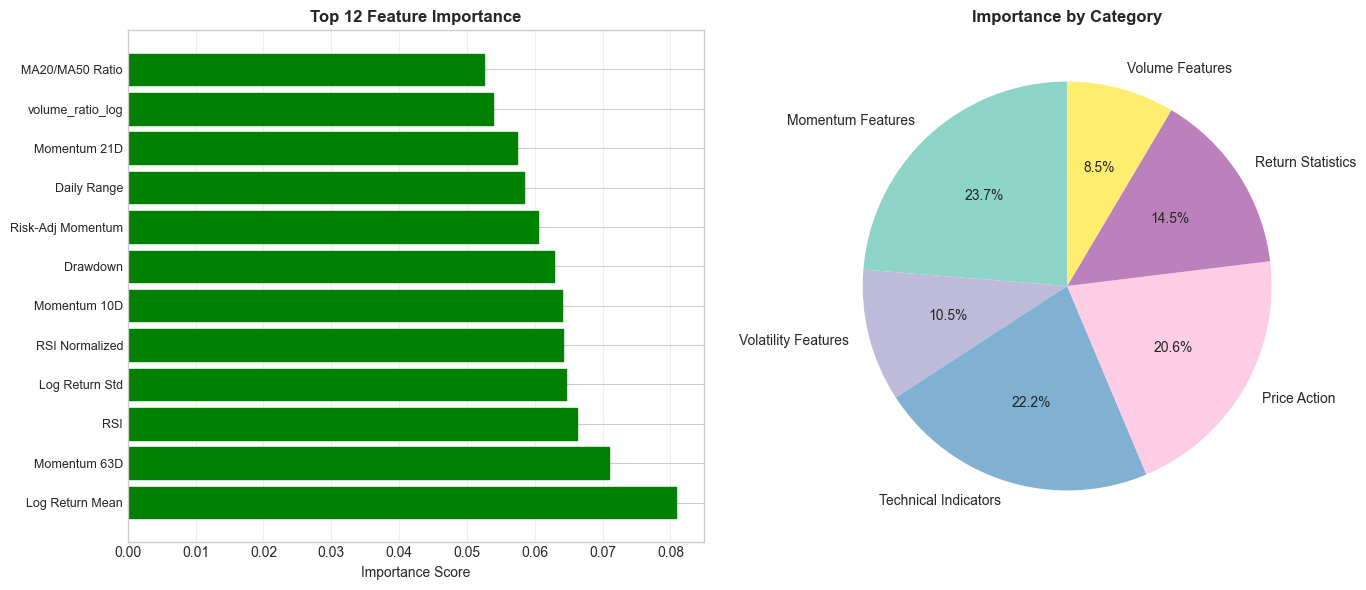


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. TOWR: 1.721%
  2. BBCA: 1.688%
  3. BBRI: 1.610%
  4. WSKT: 1.602%
  5. INCO: 1.545%
  6. BMRI: 1.503%
  7. MDKA: 1.429%
  8. INDF: 1.371%
  9. PGAS: 1.341%
 10. AKRA: 1.328%
 11. PTBA: 1.224%
 12. ASII: 1.224%
 13. ANTM: 1.215%
 14. KLBF: 1.187%
 15. SIDO: 1.179%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 0
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Bank >30% (3/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - TOWR: Predicted return 1.7% (High Momentum, Near High, Strong Trend). Key factors: RSI: 79.364, Kekuatan tre

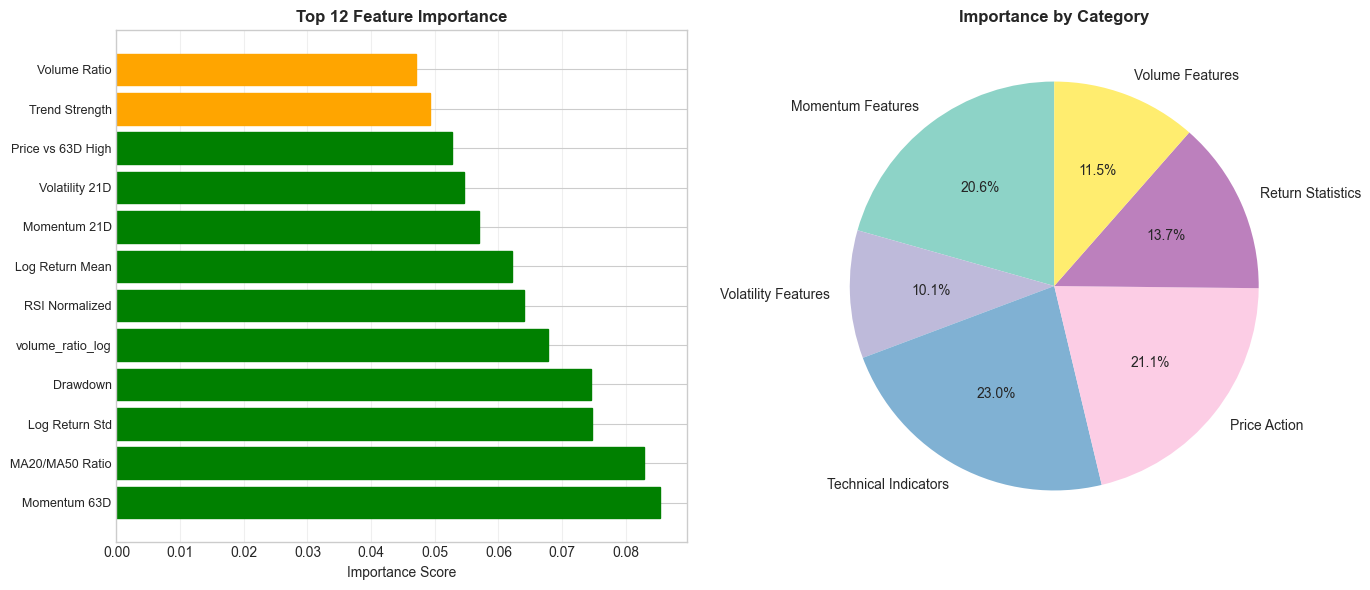


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. SMRA: 28.440%
  2. CTRA: 22.974%
  3. BRPT: 22.035%
  4. AKRA: 19.199%
  5. EXCL: 17.718%
  6. INCO: 17.498%
  7. ADRO: 17.328%
  8. MAPA: 16.600%
  9. TKIM: 16.562%
 10. INKP: 16.164%
 11. PGAS: 15.429%
 12. WSKT: 15.426%
 13. ANTM: 15.223%
 14. ERAA: 14.721%
 15. ESSA: 14.474%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 42

SECTOR CONSTRAINT CHECK
------------------------------------------------------------

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 8
 - SMRA: Predicted return 28.4% (Negative Momentum, Value Play, High Volatility, Strong Trend). Key factors: RSI: 12.821, Kekuatan trend: 10.838, Mom

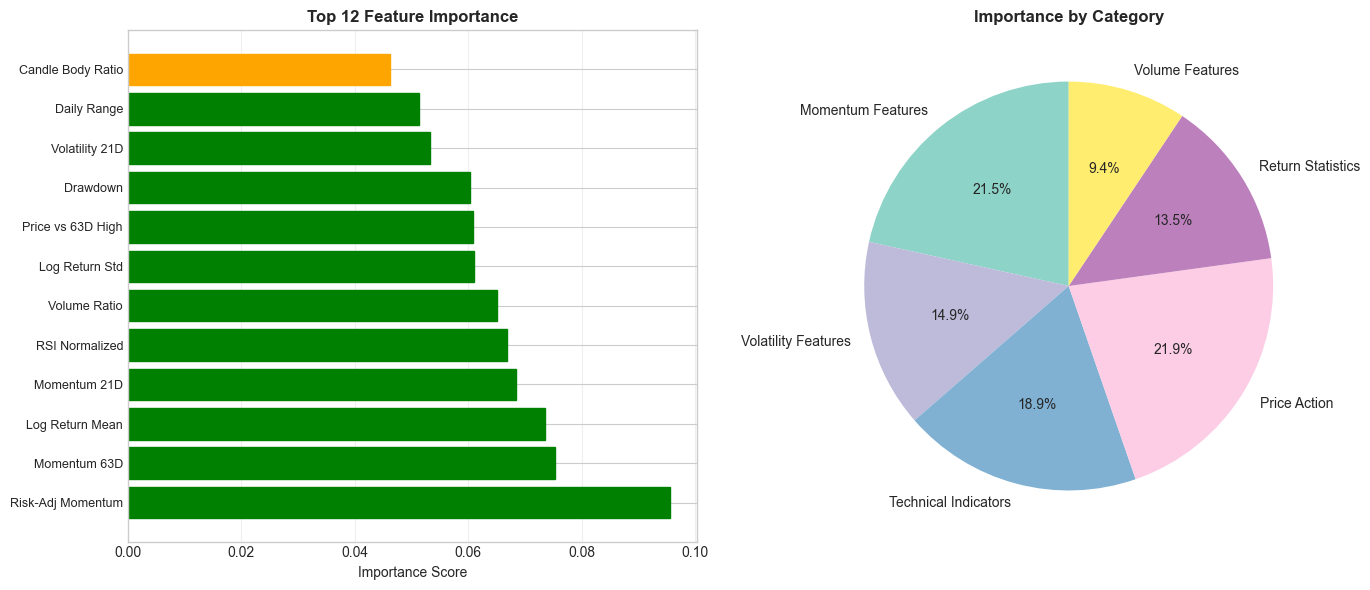


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. TOWR: 10.256%
  2. ANTM: 7.290%
  3. EXCL: 5.590%
  4. INCO: 5.382%
  5. ELSA: 5.254%
  6. BRPT: 4.394%
  7. MAPA: 4.109%
  8. ERAA: 3.923%
  9. BMRI: 3.859%
 10. BBRI: 3.816%
 11. AKRA: 3.806%
 12. TKIM: 3.764%
 13. KLBF: 3.764%
 14. ITMG: 3.709%
 15. MDKA: 3.707%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 36

SECTOR CONSTRAINT CHECK
------------------------------------------------------------

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 8
 - TOWR: Predicted return 10.3% (High Momentum, Near High, Strong Trend). Key factors: RSI: 42.500, Kekuatan trend: 2.418, Momentum teradjust risiko: 2.418. Extrem

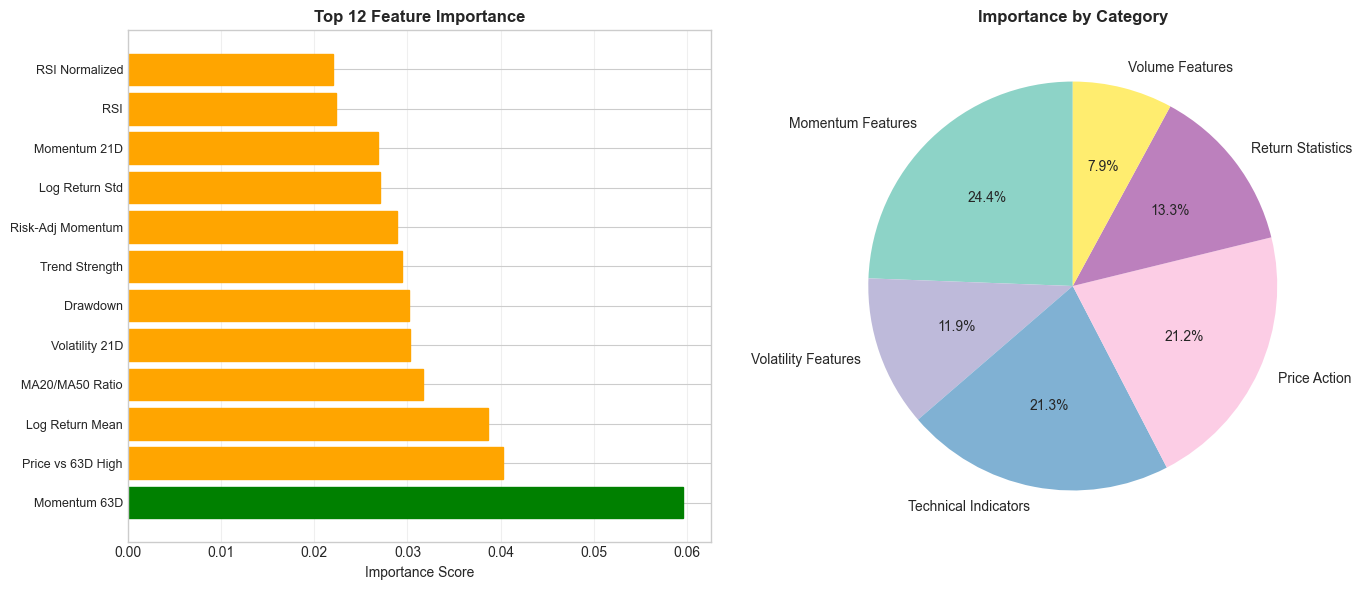


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BRPT: 2.582%
  2. WSKT: -0.407%
  3. MAPA: -2.950%
  4. MEDC: -3.150%
  5. PGAS: -3.544%
  6. ELSA: -3.580%
  7. JPFA: -3.779%
  8. BBRI: -3.841%
  9. SMRA: -3.896%
 10. INDF: -4.275%
 11. PWON: -4.332%
 12. ITMG: -4.351%
 13. SMGR: -4.468%
 14. ICBP: -4.473%
 15. MDKA: -4.565%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 1
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energi >30% (3/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - BRPT: Predicted return 2.6% (Negative Momentum, Value Play, High Volatility, Strong Trend). 

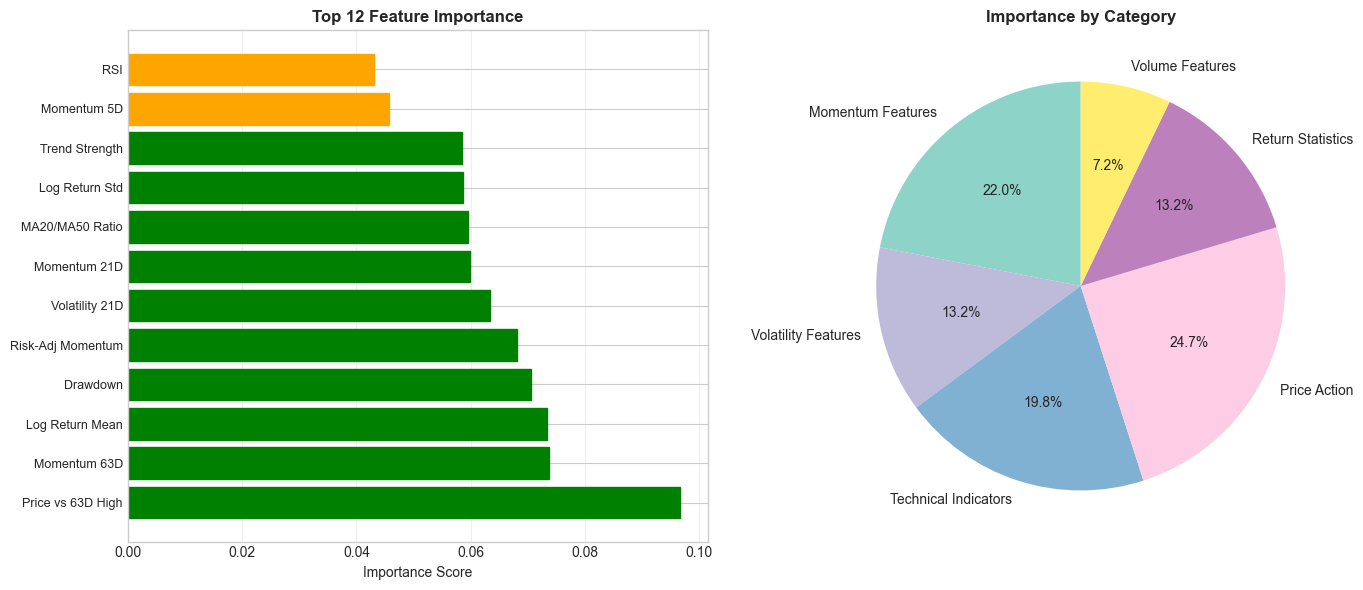


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. ANTM: 20.009%
  2. MDKA: 16.256%
  3. HRUM: 15.941%
  4. ELSA: 13.726%
  5. MEDC: 12.202%
  6. ESSA: 12.028%
  7. TKIM: 10.804%
  8. WSKT: 10.746%
  9. AKRA: 10.553%
 10. BBYB: 9.662%
 11. INTP: 9.532%
 12. SMRA: 9.407%
 13. INKP: 9.399%
 14. INCO: 9.287%
 15. CPIN: 9.265%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 42

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energi >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - ANTM: Predicted return 20.0% (High Momentum, Near High, High Volatility, Strong Trend). Key factors: RSI: 98.810, Kekuatan tren

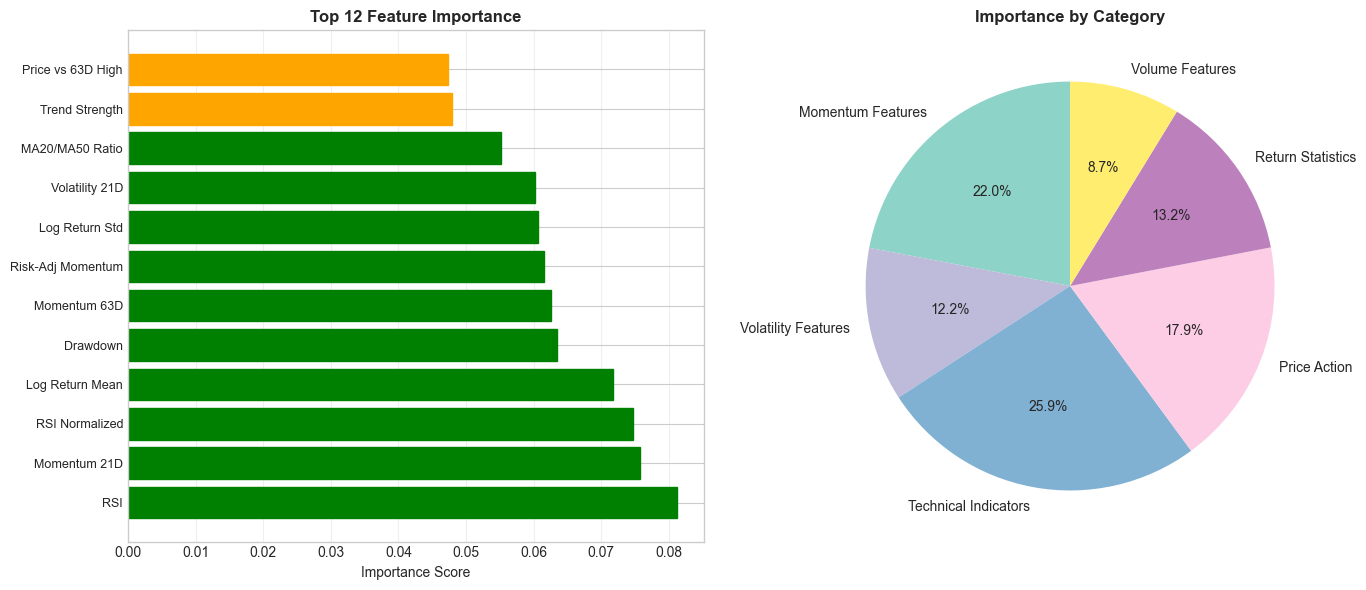


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. MAPA: 6.339%
  2. ESSA: 6.021%
  3. HRUM: 3.627%
  4. BBYB: 3.012%
  5. JPFA: 2.113%
  6. MEDC: 2.037%
  7. AKRA: 1.994%
  8. SMRA: 1.260%
  9. CTRA: 1.228%
 10. PWON: 1.170%
 11. TKIM: 1.143%
 12. INKP: 1.059%
 13. CPIN: 0.943%
 14. TLKM: 0.689%
 15. PTBA: 0.606%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energi >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 5
 - MAPA: Predicted return 6.3% (Negative Momentum). Key factors: RSI: 51.064, Rasio MA20/MA50: 0.992, Kekuatan trend: 0.934. Extreme: Drawdo

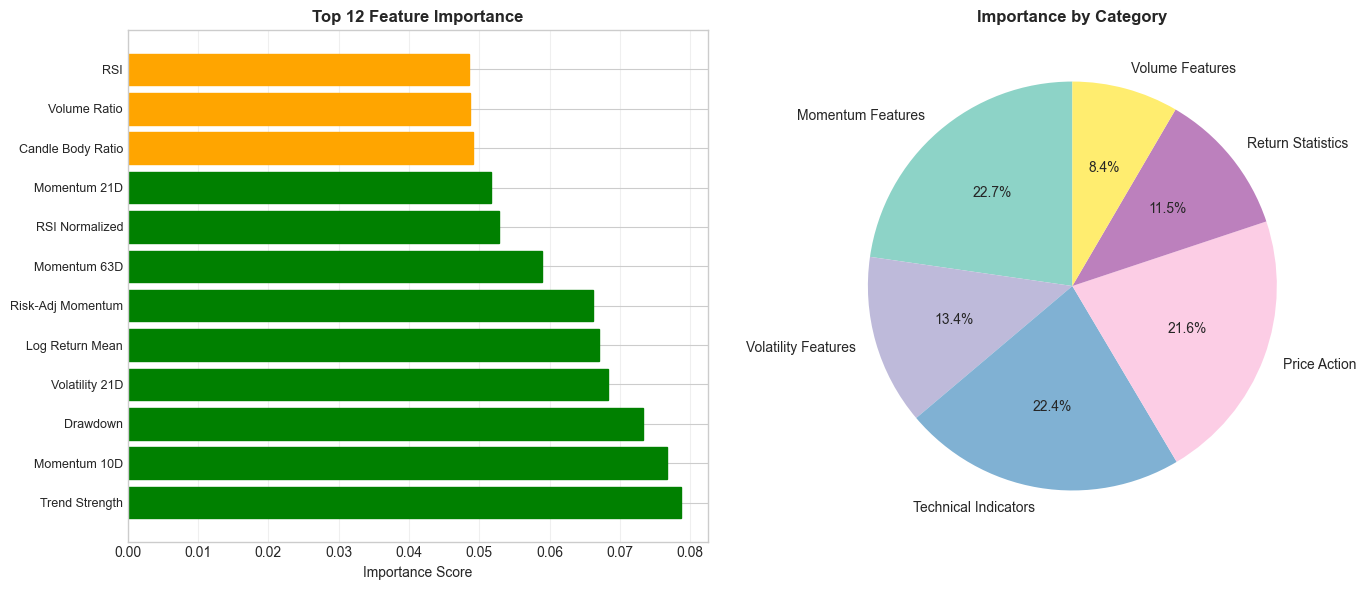


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BBYB: 8.413%
  2. WSKT: 6.299%
  3. AKRA: 4.498%
  4. MAPA: 4.263%
  5. MDKA: 4.151%
  6. INKP: 3.953%
  7. TKIM: 3.940%
  8. INTP: 3.458%
  9. PWON: 3.139%
 10. EXCL: 3.074%
 11. SMRA: 3.011%
 12. CTRA: 2.956%
 13. PGAS: 2.882%
 14. UNTR: 2.842%
 15. TLKM: 2.744%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 32

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - BBYB: Predicted return 8.4% (Negative Momentum, Value Play, High Volatility). Key factors: RSI: 50.501, Rasio MA20/MA50: 0.963, Harga 

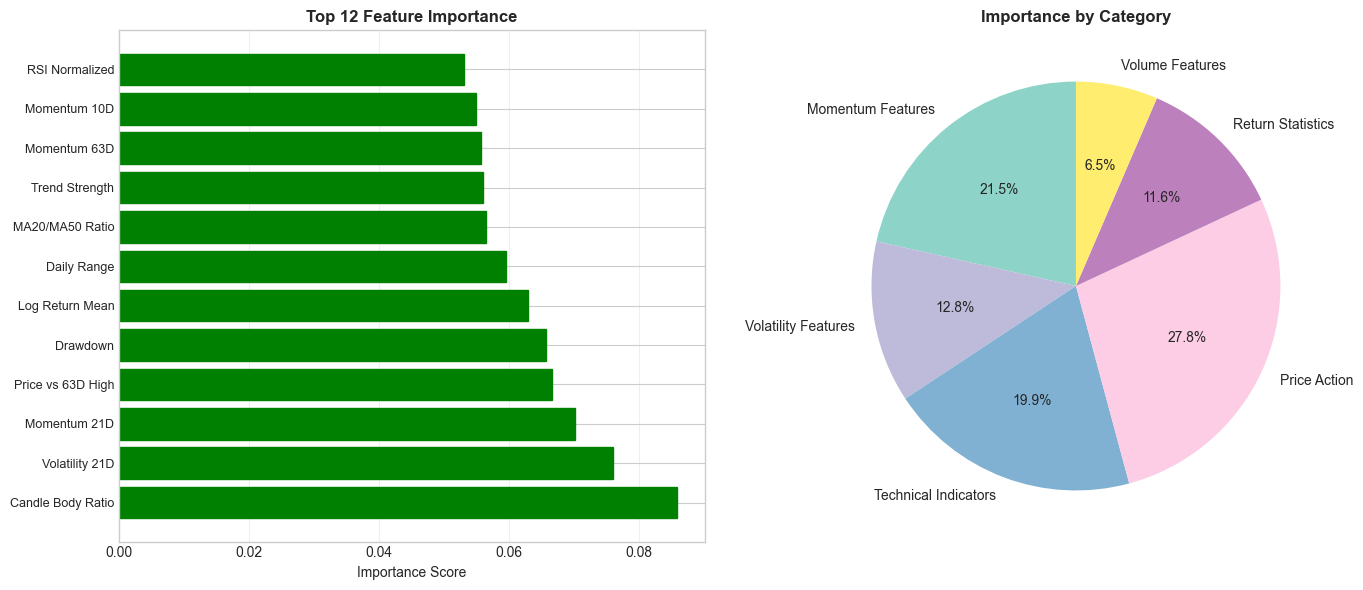


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. MEDC: 10.541%
  2. TKIM: 6.120%
  3. PGAS: 6.058%
  4. INKP: 5.371%
  5. WSKT: 4.880%
  6. UNVR: 4.744%
  7. MAPA: 4.340%
  8. INTP: 3.437%
  9. BBNI: 2.690%
 10. ASII: 2.475%
 11. AKRA: 2.326%
 12. PWON: 2.269%
 13. BRPT: 2.226%
 14. PTBA: 2.157%
 15. EXCL: 2.066%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 17

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - MEDC: Predicted return 10.5% (Negative Momentum, Value Play, High Volatility). Key factors: RSI: 40.000, Rasio body candle: 1.000, Ra

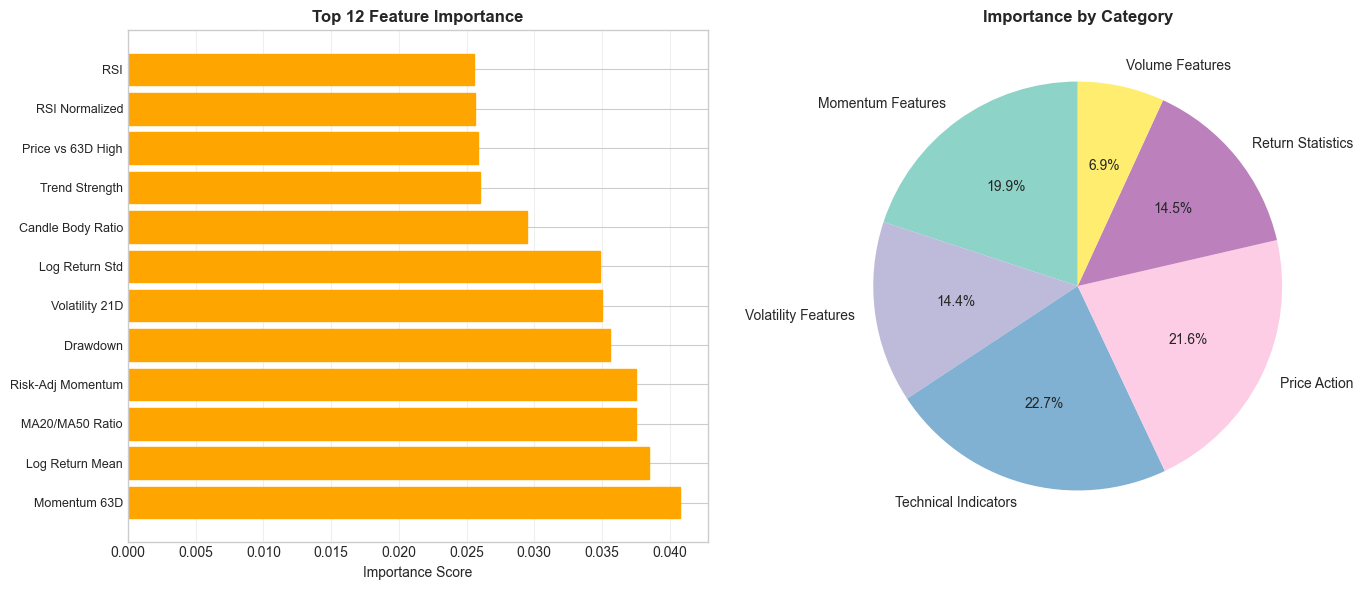


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. MDKA: 2.499%
  2. UNVR: 2.162%
  3. HRUM: 2.100%
  4. ADRO: 1.970%
  5. TKIM: 1.703%
  6. BBYB: 1.584%
  7. INTP: 1.437%
  8. SMGR: 1.405%
  9. INKP: 1.342%
 10. AKRA: 1.283%
 11. MIKA: 1.280%
 12. TLKM: 1.269%
 13. BMRI: 1.040%
 14. KLBF: 1.020%
 15. SIDO: 0.985%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 3
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Energi >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 5
 - MDKA: Predicted return 2.5% (High Momentum, Near High, Strong Trend). Key factors: RSI: 67.257, Kekuatan t

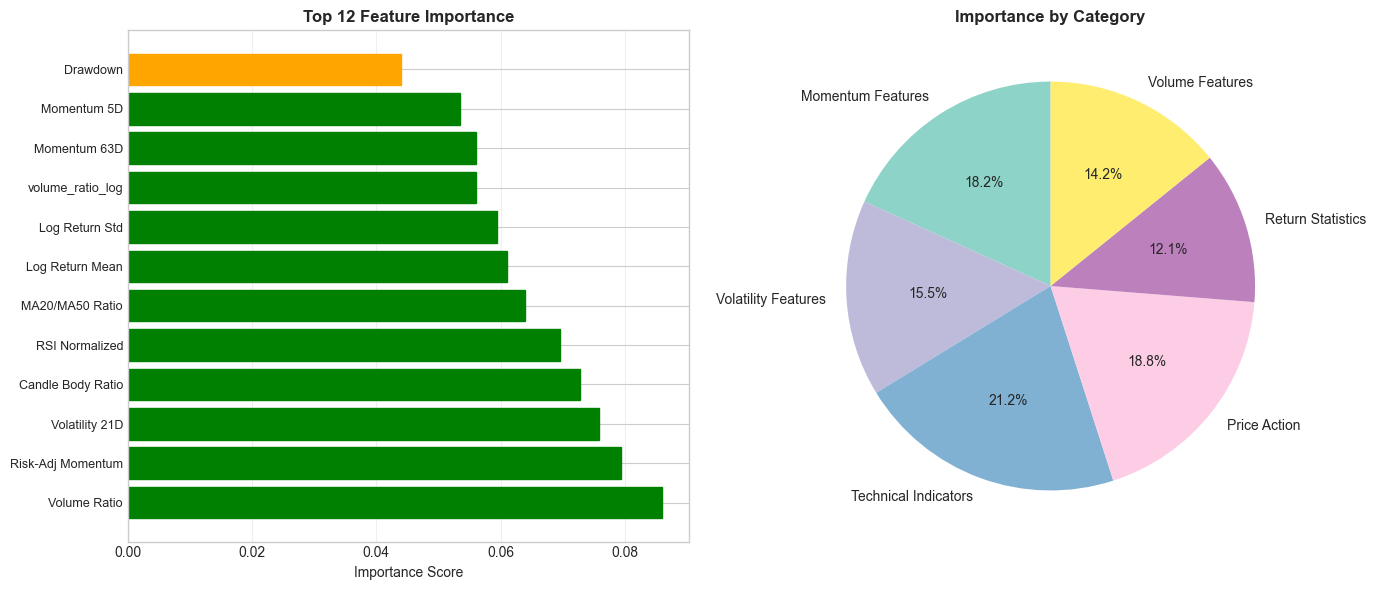


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. ESSA: 17.754%
  2. INKP: 10.099%
  3. TKIM: 9.038%
  4. ANTM: 8.266%
  5. PTBA: 8.236%
  6. ITMG: 7.991%
  7. ELSA: 7.980%
  8. INCO: 7.765%
  9. ADRO: 7.757%
 10. MAPA: 7.575%
 11. PGAS: 7.475%
 12. MEDC: 6.858%
 13. HRUM: 6.377%
 14. MDKA: 5.666%
 15. WSKT: 5.026%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 38

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/8)
Sector Energi >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 6
 - ESSA: Predicted return 17.8% (High Momentum, Near High, High Volatility, Strong Trend). Key factors: RSI: 6

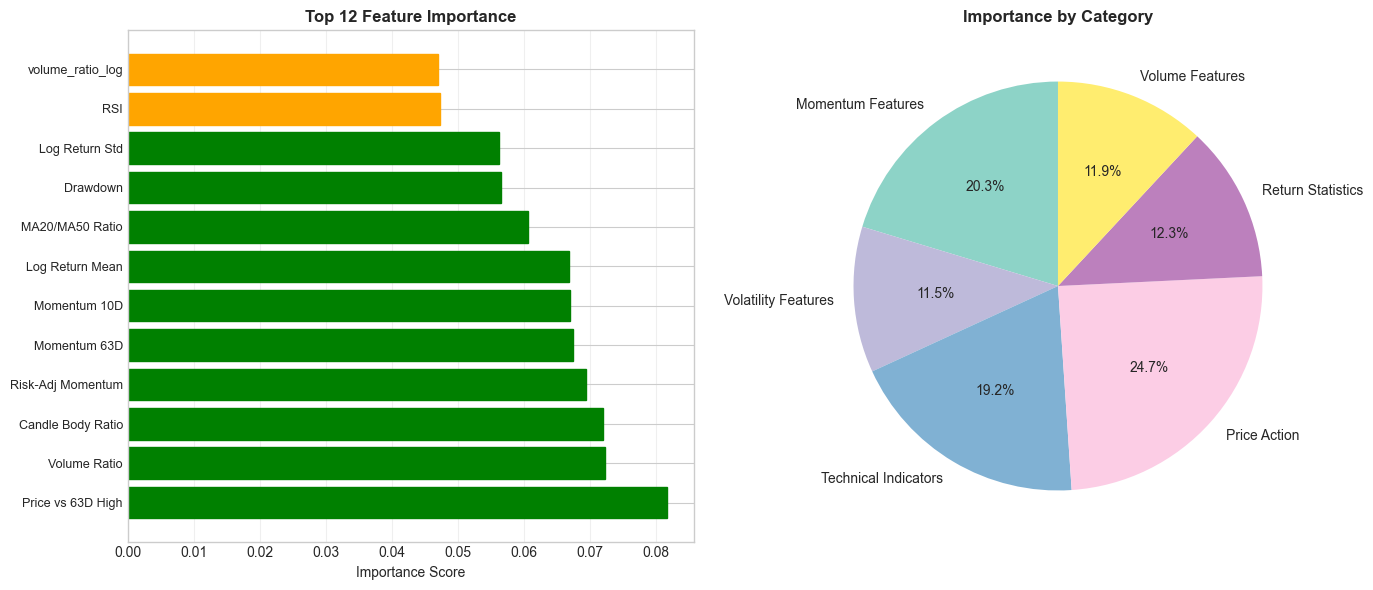


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. INKP: 5.927%
  2. BBYB: 5.769%
  3. TKIM: 4.697%
  4. WSKT: 4.356%
  5. MEDC: 4.345%
  6. PTBA: 3.148%
  7. INTP: 3.128%
  8. JPFA: 2.671%
  9. MAPA: 2.589%
 10. SMRA: 2.579%
 11. ITMG: 2.200%
 12. UNVR: 2.161%
 13. PGAS: 2.134%
 14. SMGR: 1.986%
 15. ADRO: 1.962%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 13

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - INKP: Predicted return 5.9% (High Momentum, Near High, Strong Trend, High Volume). Key factors: RSI: 70.787, Kekuatan trend: 4.716, Mo

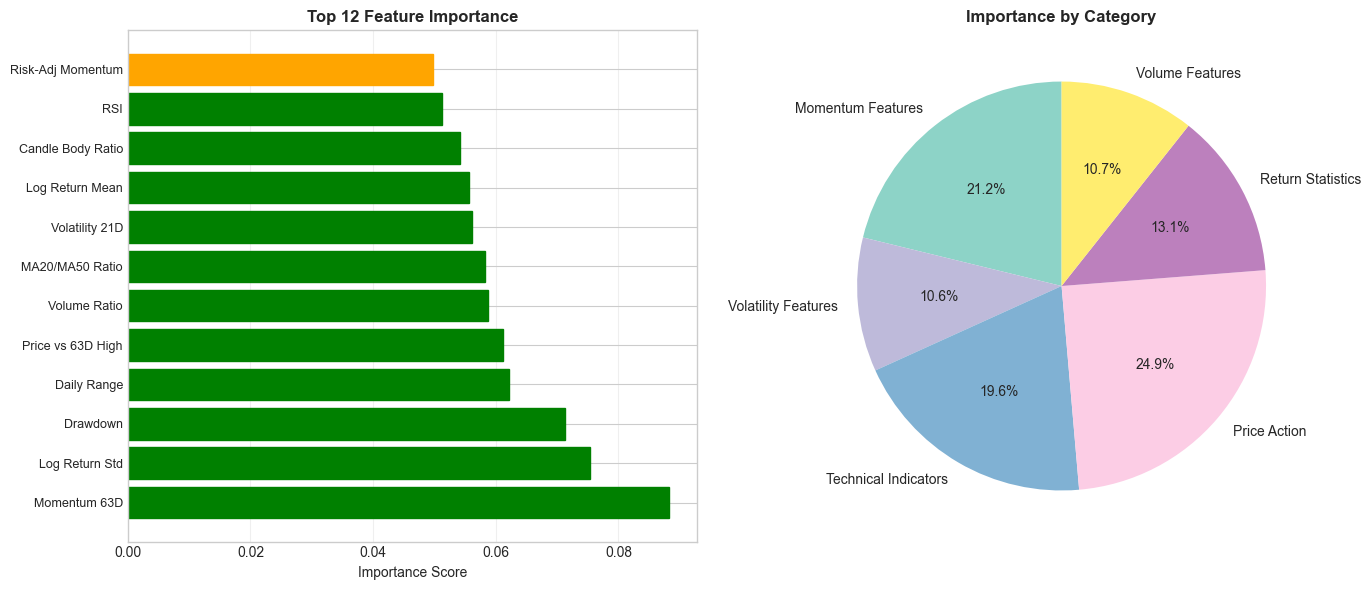


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. TKIM: 6.127%
  2. MEDC: 6.008%
  3. INKP: 5.283%
  4. UNVR: 3.531%
  5. WSKT: 2.973%
  6. SMGR: 2.967%
  7. MAPA: 2.808%
  8. INCO: 2.633%
  9. INTP: 2.584%
 10. HRUM: 2.479%
 11. BBCA: 2.430%
 12. BMRI: 1.904%
 13. ELSA: 1.890%
 14. SMRA: 1.842%
 15. JPFA: 1.790%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 11

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - TKIM: Predicted return 6.1% (Near High, Strong Trend). Key factors: RSI: 72.000, Kekuatan trend: 5.496, Momentum teradjust risiko: 5.4

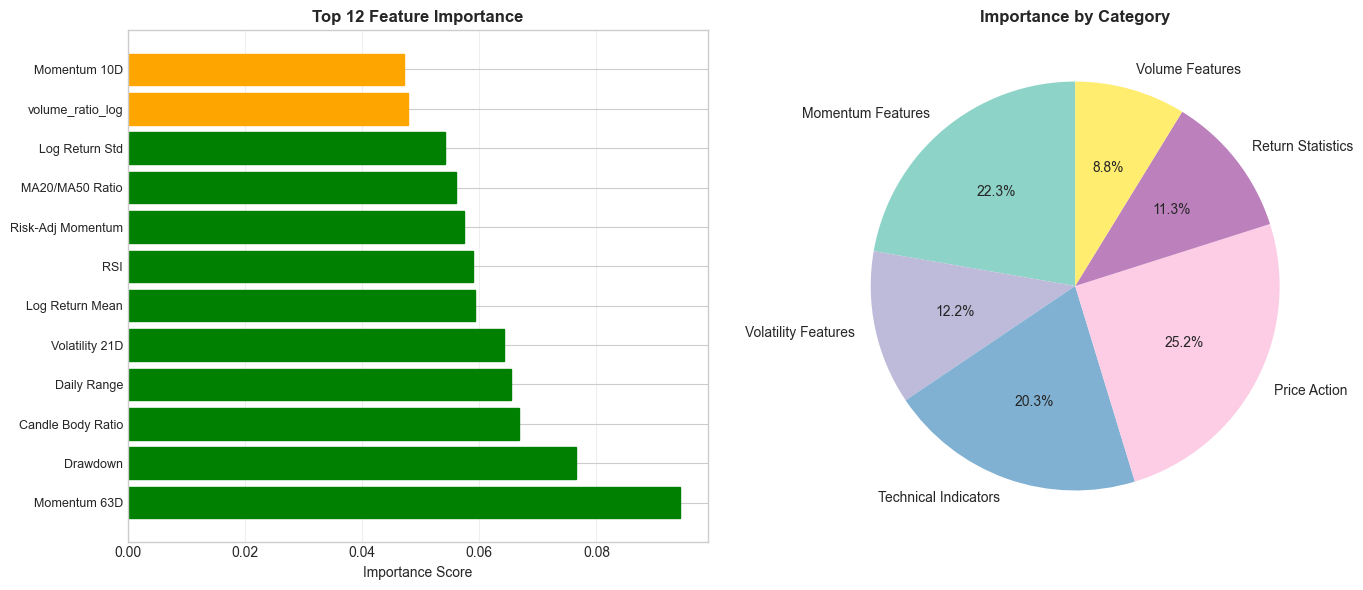


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. SMRA: 6.548%
  2. BBYB: 5.592%
  3. WSKT: 5.326%
  4. INTP: 5.019%
  5. TKIM: 4.662%
  6. JPFA: 4.571%
  7. MDKA: 4.417%
  8. BBCA: 4.355%
  9. INKP: 4.314%
 10. PWON: 4.237%
 11. CTRA: 4.115%
 12. KLBF: 4.063%
 13. BBRI: 3.932%
 14. ESSA: 3.919%
 15. SMGR: 3.903%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 43

SECTOR CONSTRAINT CHECK
------------------------------------------------------------

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 8
 - SMRA: Predicted return 6.5% (High Momentum, Strong Trend, High Volume). Key factors: RSI: 73.913, Kekuatan trend: 1.578, Momentum teradjust risiko: 1.578. Extrem

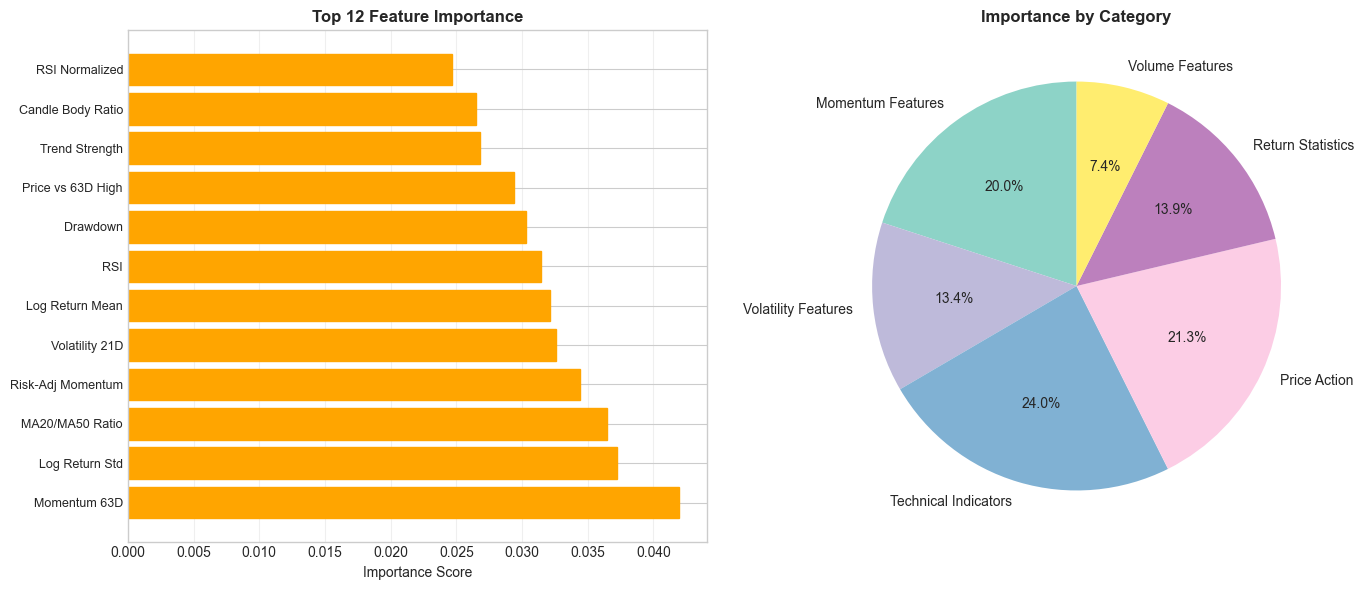


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. TKIM: 3.914%
  2. INKP: 2.637%
  3. SMRA: 2.535%
  4. JPFA: 2.455%
  5. WSKT: 2.243%
  6. MEDC: 2.123%
  7. BBYB: 2.064%
  8. UNVR: 2.042%
  9. INTP: 1.940%
 10. MAPA: 1.867%
 11. BRPT: 1.847%
 12. SIDO: 1.594%
 13. AMRT: 1.559%
 14. ANTM: 1.555%
 15. SMGR: 1.546%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 8

SECTOR CONSTRAINT CHECK
------------------------------------------------------------

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 8
 - TKIM: Predicted return 3.9% (Negative Momentum, Strong Trend). Key factors: RSI: 29.730, Kekuatan trend: 1.527, Momentum teradjust risiko: -1.527
 - INKP: Predict

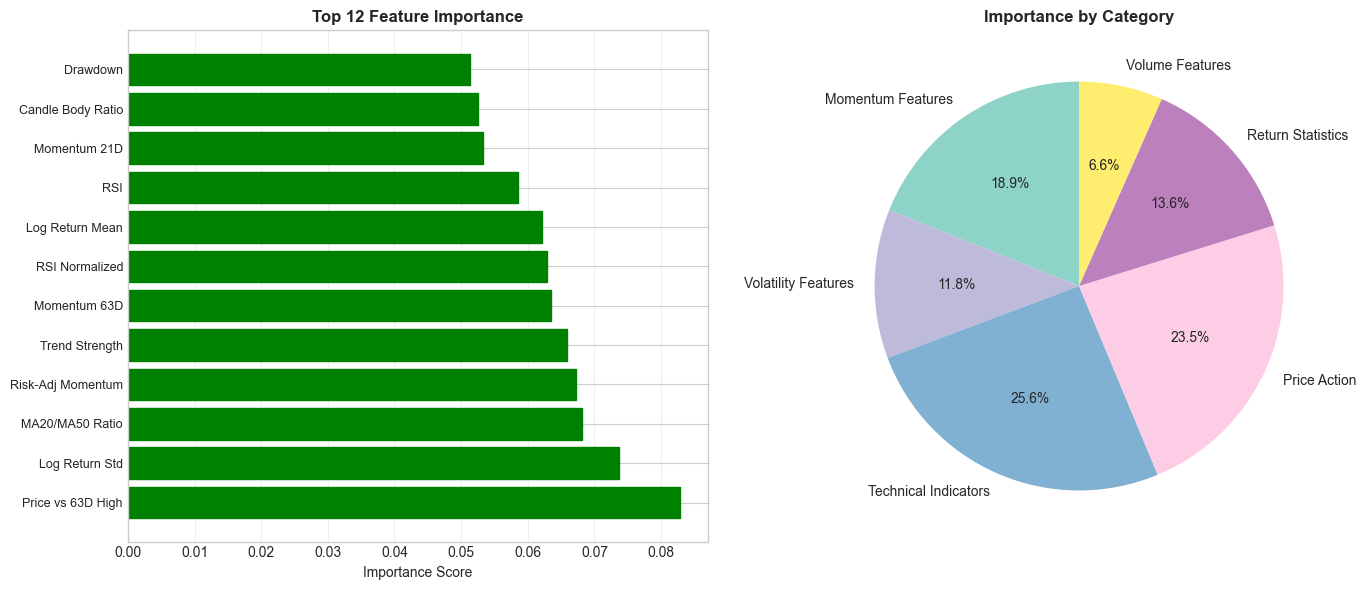


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. ESSA: 5.381%
  2. JPFA: 4.420%
  3. SMGR: 3.161%
  4. SMRA: 2.436%
  5. UNVR: 2.341%
  6. BBYB: 1.936%
  7. MEDC: 1.892%
  8. ICBP: 1.846%
  9. INTP: 1.800%
 10. INKP: 1.674%
 11. CPIN: 1.658%
 12. BBRI: 1.654%
 13. BUKA: 1.654%
 14. MAPA: 1.598%
 15. GOTO: 1.530%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 5
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (2/6)
Sector Konsumer >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - ESSA: Predicted return 5.4% (Negative Momentum, Value Play, High Volatility, 

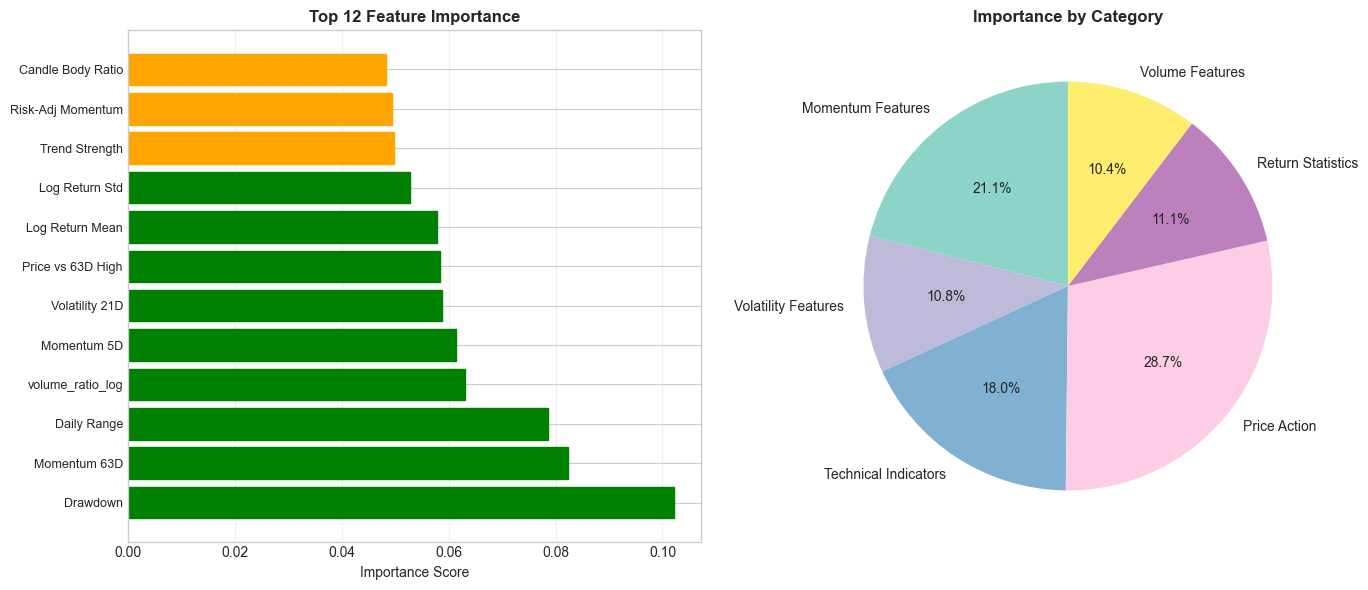


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BBYB: 3.339%
  2. SMRA: 0.873%
  3. ERAA: 0.646%
  4. JPFA: 0.303%
  5. GOTO: 0.256%
  6. BRPT: -0.032%
  7. UNVR: -0.044%
  8. WSKT: -0.053%
  9. SMGR: -0.200%
 10. INTP: -0.241%
 11. BUKA: -0.396%
 12. SIDO: -0.819%
 13. PGAS: -0.867%
 14. CTRA: -1.042%
 15. AMRT: -1.242%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 1
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 6
 - BBYB: Predicted return 3.3% (High Momentum, High Volatility, High Volume). Key factors: RSI: 64.000, Rasio volume: 3.321,

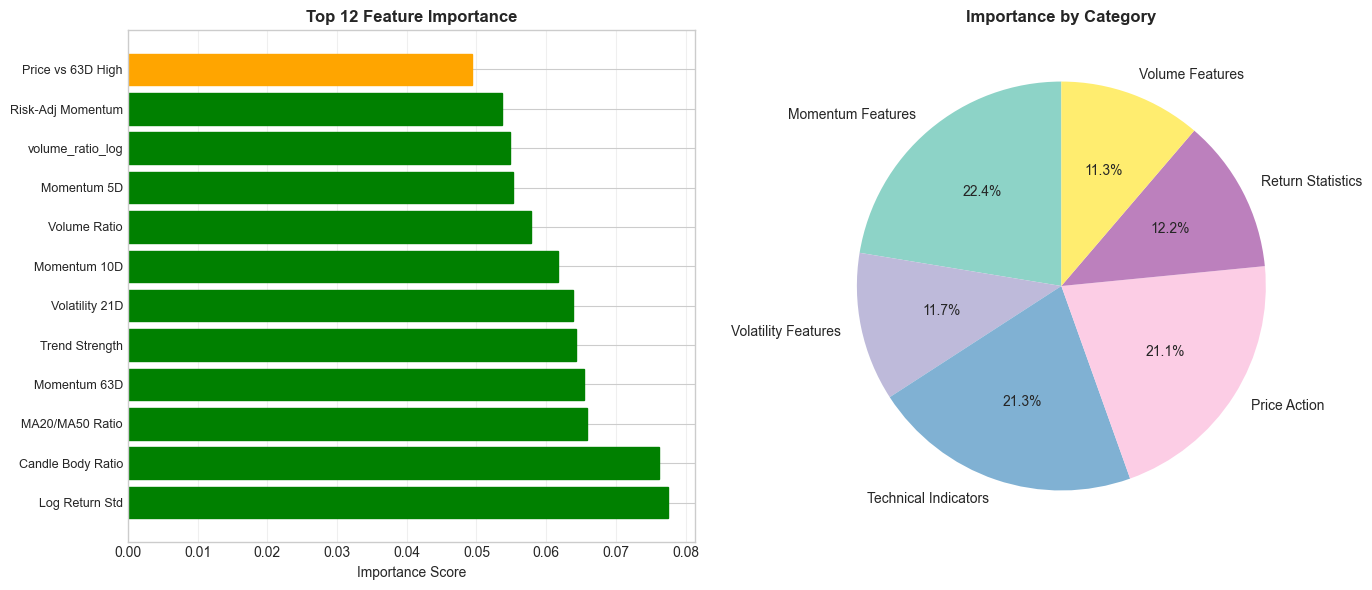


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. JPFA: 1.613%
  2. SMRA: 1.561%
  3. TKIM: 1.119%
  4. UNVR: 1.070%
  5. BUKA: 0.932%
  6. PTBA: 0.848%
  7. SMGR: 0.686%
  8. WSKT: 0.669%
  9. EXCL: 0.607%
 10. PWON: 0.600%
 11. TOWR: 0.541%
 12. MIKA: 0.499%
 13. ELSA: 0.477%
 14. SIDO: 0.394%
 15. INCO: 0.350%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 0
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Konsumer >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 5
 - JPFA: Predicted return 1.6% (High Momentum, Near High, Strong Trend). Key factors: RSI: 65.790, Kekuatan

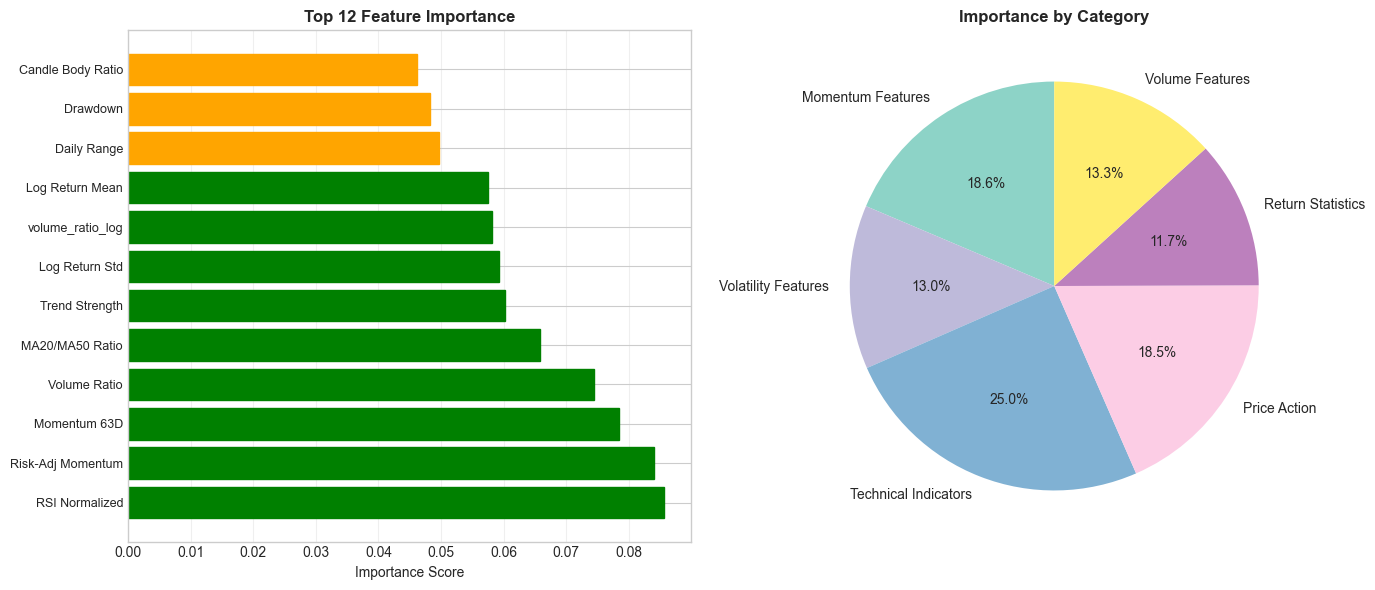


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. TOWR: 1.298%
  2. INTP: 1.097%
  3. ANTM: 0.545%
  4. INKP: 0.540%
  5. HRUM: 0.487%
  6. ADRO: 0.473%
  7. ICBP: 0.342%
  8. BUKA: 0.318%
  9. SMGR: 0.290%
 10. PTBA: 0.140%
 11. TKIM: 0.136%
 12. MDKA: 0.019%
 13. ERAA: -0.036%
 14. UNTR: -0.068%
 15. BMRI: -0.079%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 0
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (2/6)
Sector Energi >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - TOWR: Predicted return 1.3% (Near High, Strong Trend, High Volume). Key fact

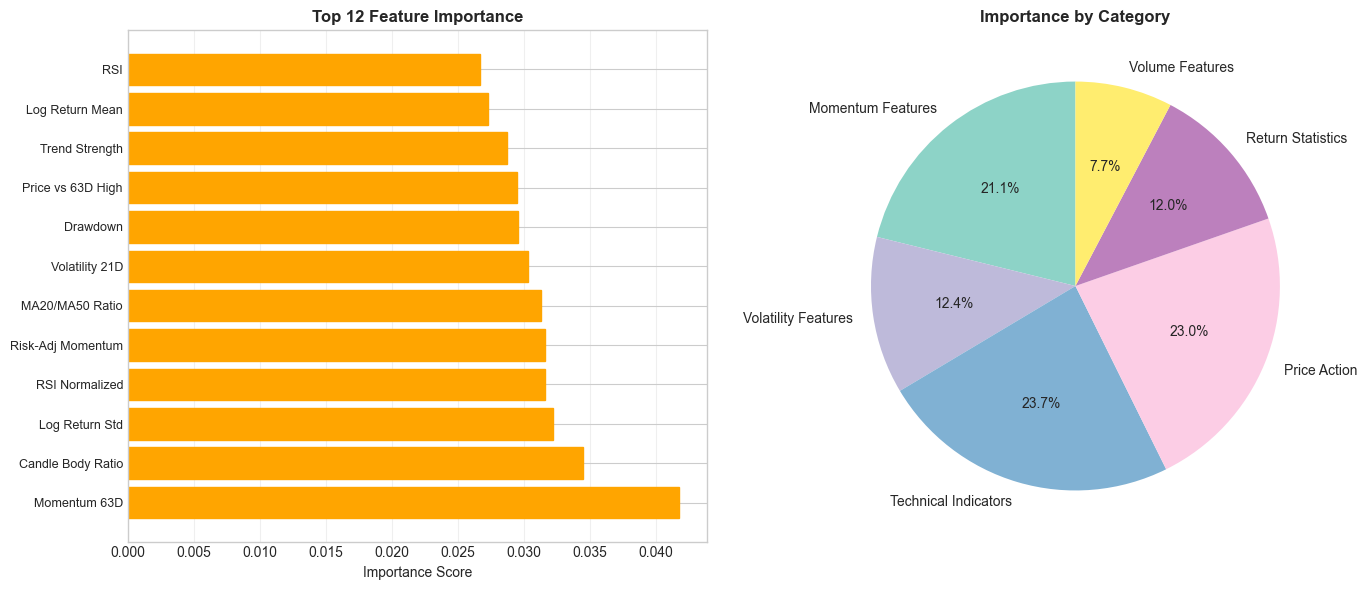


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. WSKT: 2.228%
  2. INTP: 1.902%
  3. INDF: 1.765%
  4. ANTM: 1.504%
  5. UNTR: 1.438%
  6. UNVR: 1.334%
  7. CPIN: 1.295%
  8. BBYB: 1.266%
  9. PGAS: 1.220%
 10. AMRT: 1.103%
 11. JPFA: 1.068%
 12. INKP: 0.866%
 13. EXCL: 0.829%
 14. MAPA: 0.682%
 15. ITMG: 0.491%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 1
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (2/6)
Sector Konsumer >30% (2/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - WSKT: Predicted return 2.2% (Near High). Key factors: Rasio volume: 1.000, RS

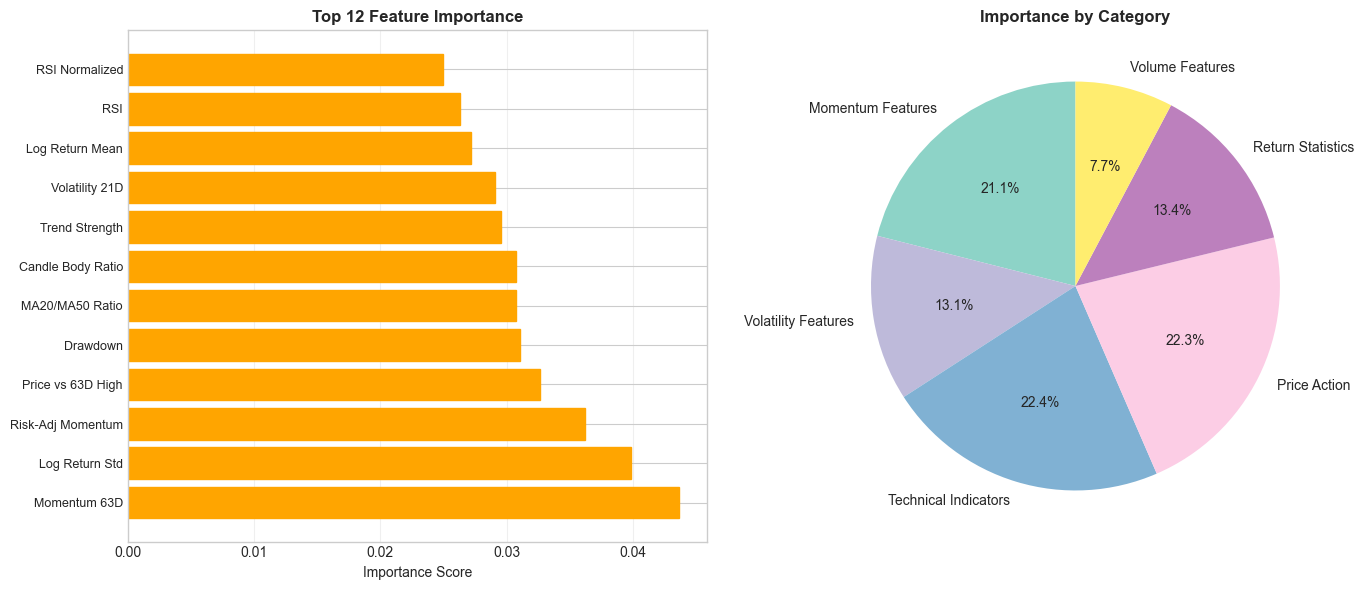


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BBYB: 6.514%
  2. INCO: 6.272%
  3. AMMN: 5.347%
  4. HRUM: 4.723%
  5. MAPA: 4.551%
  6. BRPT: 4.235%
  7. ANTM: 4.133%
  8. ERAA: 3.615%
  9. UNVR: 3.546%
 10. SMGR: 3.219%
 11. MDKA: 2.988%
 12. AMRT: 2.750%
 13. AKRA: 2.185%
 14. INTP: 1.519%
 15. BUKA: 1.316%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 13

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Pertambangan >30% (3/8)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 7
 - BBYB: Predicted return 6.5% (High Momentum, Near High, High Volatility, Strong Trend, High Volume). Key factors: RSI: 70.866, Keku

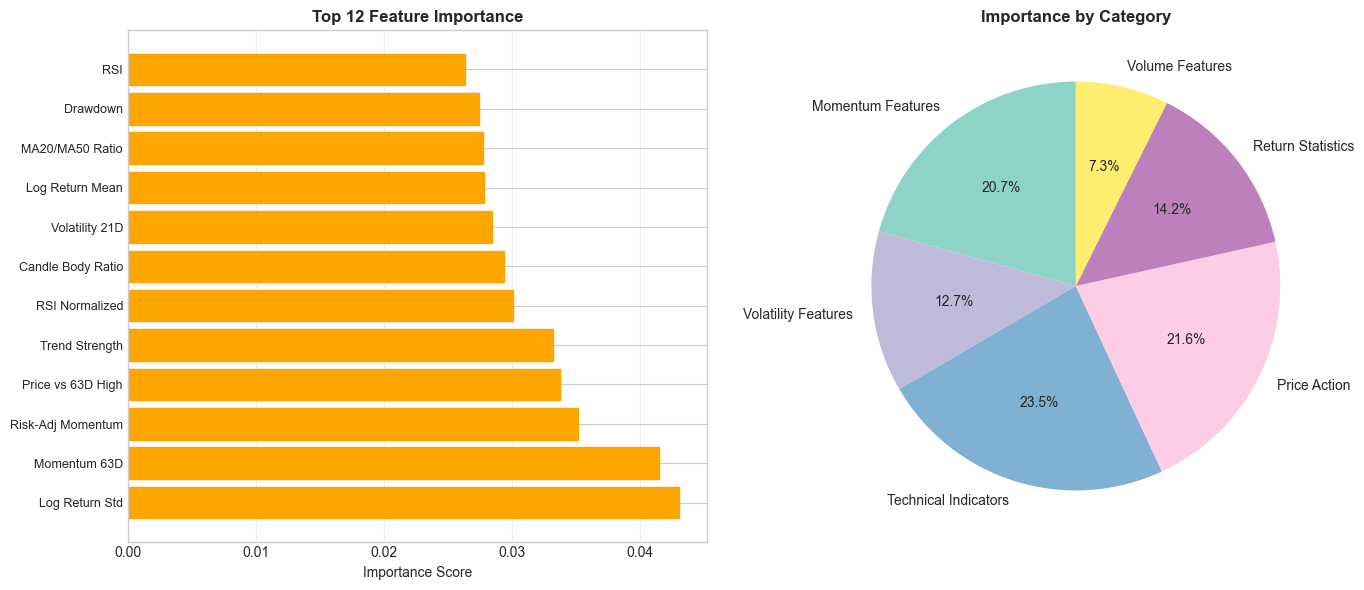


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BRPT: 4.287%
  2. INKP: 1.820%
  3. TKIM: 1.605%
  4. UNTR: 1.578%
  5. UNVR: 1.520%
  6. BBYB: 0.793%
  7. GOTO: 0.549%
  8. HRUM: 0.511%
  9. BUKA: 0.474%
 10. PWON: 0.395%
 11. TOWR: 0.263%
 12. SMRA: 0.134%
 13. INDF: 0.106%
 14. ASII: 0.037%
 15. ADRO: -0.080%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 1
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (4/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 3
 - BRPT: Predicted return 4.3% (High Momentum, Near High, High Volatility, Strong Trend). Key factors: RSI

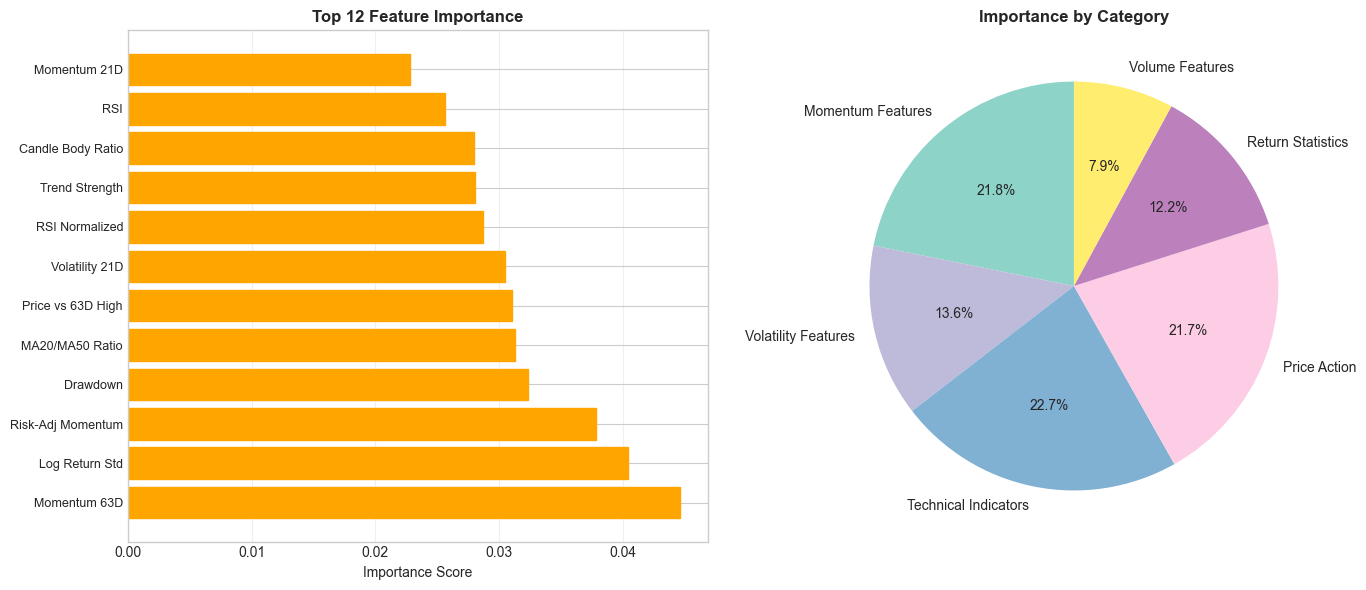


PREDICTION
------------------------------------------------------------
Extracting latest features...
Making predictions...

Top Predicted Returns
------------------------------------------------------------
(Top 15 stocks)
  1. BRPT: 2.399%
  2. INKP: 2.200%
  3. INTP: 1.893%
  4. MEDC: 1.756%
  5. BUKA: 1.719%
  6. BBYB: 1.575%
  7. HRUM: 1.531%
  8. TKIM: 1.515%
  9. GOTO: 1.449%
 10. UNVR: 1.337%
 11. JPFA: 1.222%
 12. SMGR: 1.201%
 13. MDKA: 1.180%
 14. WSKT: 1.160%
 15. MAPA: 1.075%

STOCK SELECTION
------------------------------------------------------------
Return threshold       : 2.0%
Stocks above threshold : 2
Selected candidates    : top 6

SECTOR CONSTRAINT CHECK
------------------------------------------------------------
Sector Industri >30% (3/6)

MODEL EXPLANATIONS (Selected Stocks)
------------------------------------------------------------
Stocks analyzed : 4
 - BRPT: Predicted return 2.4% (High Momentum, High Volatility, Strong Trend). Key factors: RSI: 50.704, Ke

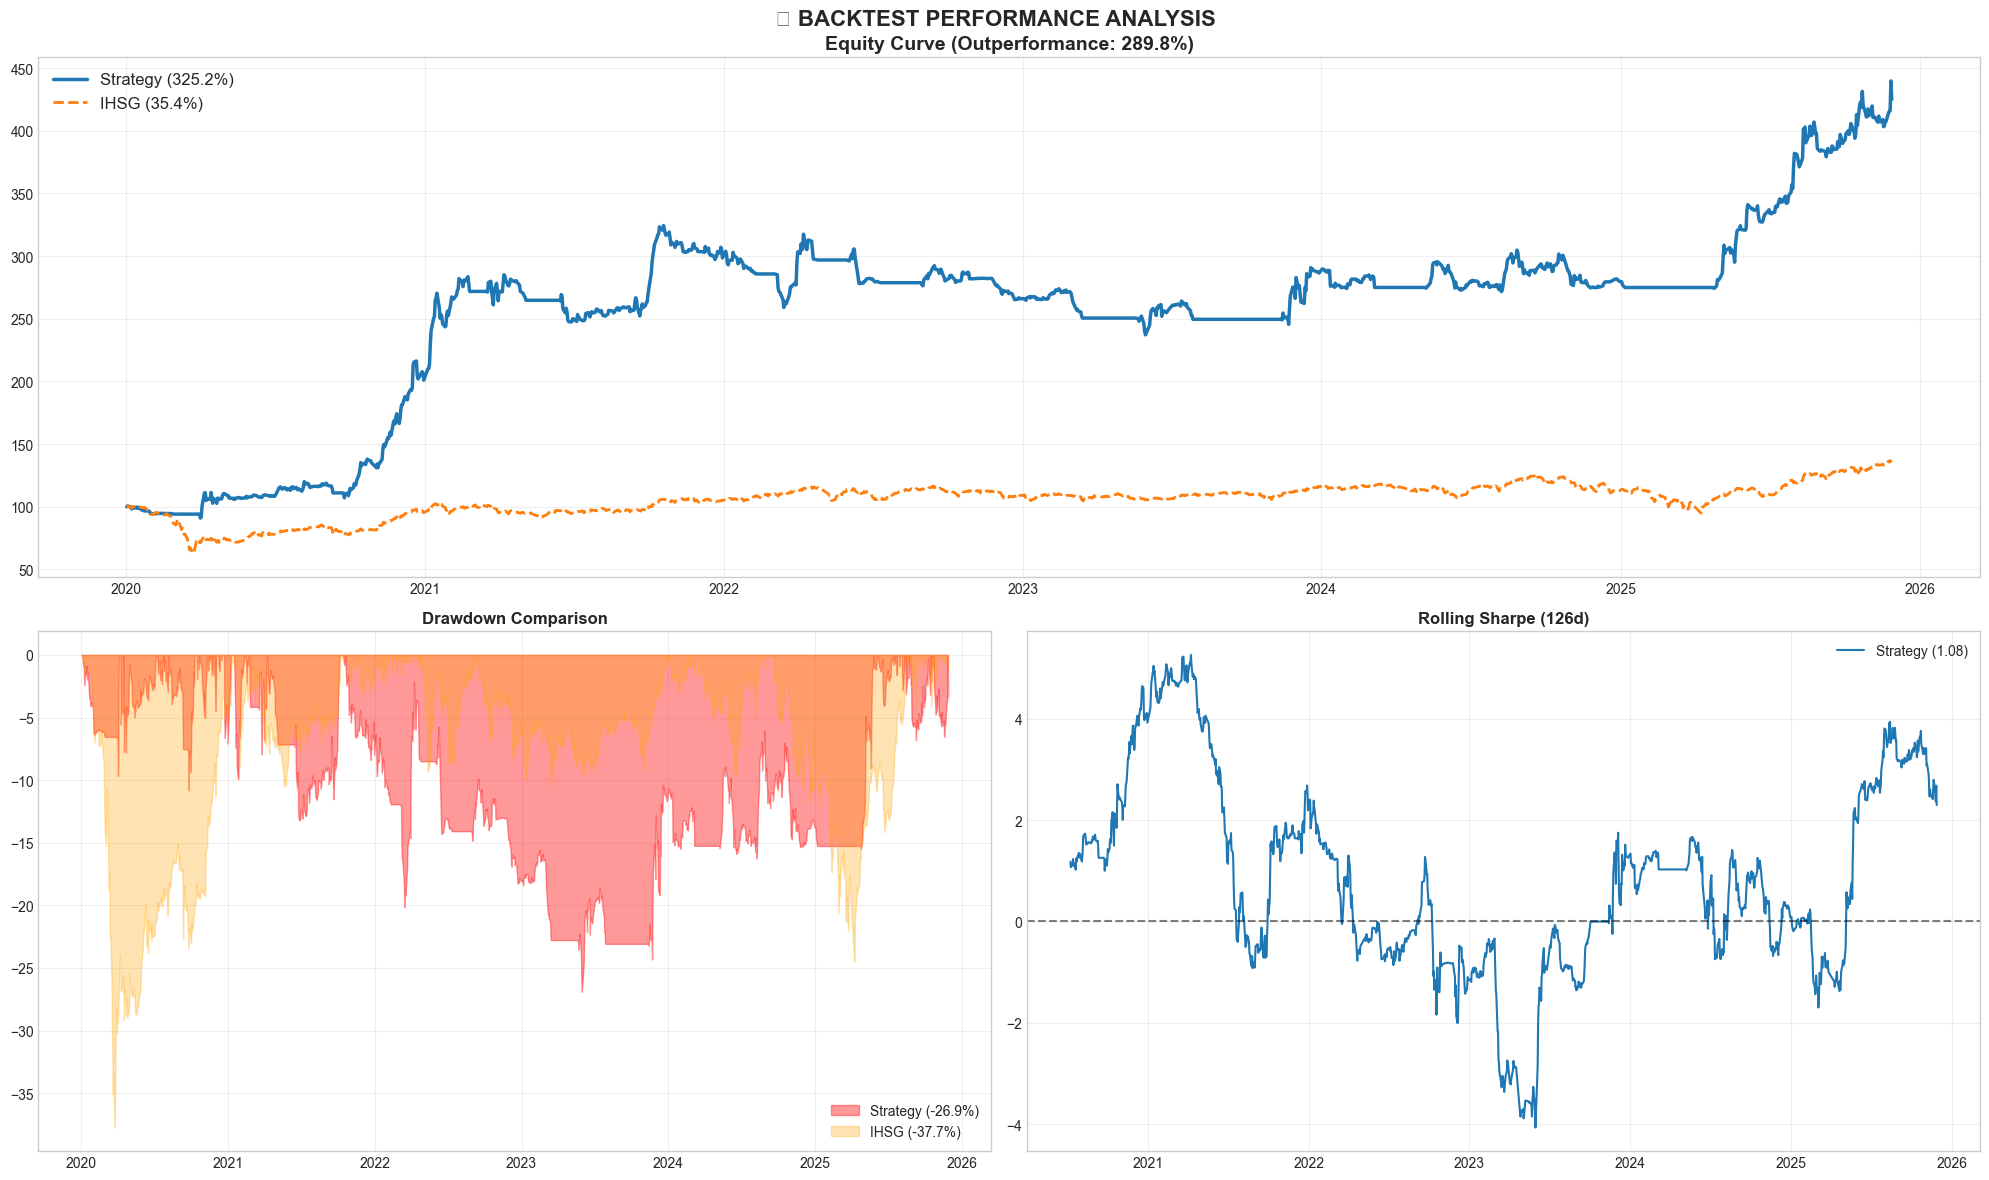


BACKTEST COMPLETED
Final Portfolio Value: Rp 424,335,482
Initial Investment: Rp 99,800,396
Total Gain: Rp 324,535,086


In [17]:
# Run backtest
print("BACKTEST RUN")

results = recommender.run_backtest(
    BACKTEST_START,
    BACKTEST_STOP,
    freq=REBAL_FREQ
)

print("\nBACKTEST COMPLETED")
print(f"Final Portfolio Value: Rp {results.iloc[-1]:,.0f}")
print(f"Initial Investment: Rp {results.iloc[0]:,.0f}")
print(f"Total Gain: Rp {results.iloc[-1] - results.iloc[0]:,.0f}")

## Cell 18: Display XAI Insights

In [18]:
# Print comprehensive XAI summary
recommender.print_xai_summary()


XAI SUMMARY ACROSS REBALANCES

FEATURE CATEGORY ANALYSIS (AVERAGE):
------------------------------------------------------------------------------------------
Category                  Contribution (%)          Top Indicators
------------------------------------------------------------------------------------------
Price Action              22.6%                     Drawdown, Price vs 63D High
Technical Indicators      21.7%                     MA20/MA50 Ratio, RSI Normalized
Momentum Features         21.2%                     Momentum 63D, Momentum 21D
Return Statistics         12.7%                     Log Return Std, Log Return Mean
Volatility Features       12.4%                     Risk-Adj Momentum, Volatility 21D
Volume Features           9.4%                      Volume Ratio, volume_ratio_log

MOST COMMON STOCK CATEGORIES:
 - Strong Trend: 101 selections (27.3%)
 - High Volatility: 63 selections (17.0%)
 - Near High: 62 selections (16.8%)
 - High Momentum: 58 selections (15.7

## Cell 19: Export Results

In [19]:
# Export results to CSV
results_df = results.to_frame('Portfolio Value')
results_df['Return %'] = results_df['Portfolio Value'].pct_change() * 100
results_df['Cumulative Return %'] = ((results_df['Portfolio Value'] / results_df['Portfolio Value'].iloc[0]) - 1) * 100

# Save to CSV
results_df.to_csv('backtest_results.csv')
print("Results exported to 'backtest_results.csv'")

# Display summary statistics
print("\nSUMMARY STATISTICS:")
print("-" * 50)
print(results_df.describe())

Results exported to 'backtest_results.csv'

SUMMARY STATISTICS:
--------------------------------------------------
       Portfolio Value     Return %  Cumulative Return %
count     1.427000e+03  1426.000000          1427.000000
mean      2.572470e+08     0.110339           157.761470
std       7.244983e+07     1.336332            72.594728
min       9.074856e+07    -5.572017            -9.069936
25%       2.500625e+08    -0.304120           150.562636
50%       2.743996e+08     0.000000           174.948363
75%       2.863080e+08     0.330349           186.880629
max       4.389230e+08    10.751642           339.800869
